# TRƯỜNG ĐẠI HỌC KHOA HỌC TỰ NHIÊN - ĐHQGHN
## KHOA TOÁN - CƠ - TIN HỌC | BỘ MÔN TIN HỌC
### MÔN HỌC: MAT3562 - THỊ GIÁC MÁY TÍNH (COMPUTER VISION)

---
# BÀI THỰC HÀNH LAB 07: PHÂN TÍCH VÙNG ẢNH NHỊ PHÂN VÀ HÌNH DẠNG ĐƯỜNG BIÊN

**Học viên / Sinh viên thực hiện:** Vũ Tiến Đạt (`23000111`)  
**Nội dung thực hành (theo `debai.txt`):**
1. **Phần 1: Xây dựng cấu trúc cây cho các vùng ảnh nhị phân & Truy vấn vùng**
   - Cho ảnh đầu vào, thực hiện nhị phân hóa (Otsu / Ngưỡng cố định / Thích nghi).
   - Xây dựng cấu trúc cây bao hàm (Region Containment Tree) cho các vùng liên thông nhị phân:
     - Mỗi nút (node) trên cây là 1 vùng liên thông **Đen (`0`)** hoặc **Trắng (`255`)**.
     - Nếu 1 vùng đen chứa vùng trắng bên trong thì vùng trắng là **nút con** của vùng đen đó và ngược lại (quan hệ bao hàm cha - con đan xen Đen $\leftrightarrow$ Trắng).
   - Trên tập ảnh tự chọn (`tap_anh/`):
     - **Yêu cầu 1.1:** Hiển thị những vùng có **kích thước** (Width, Height, diện tích hộp bao) và **diện tích thực** (số điểm ảnh) nằm trong phạm vi cho trước.
     - **Yêu cầu 1.2:** Hiển thị những vùng có chính xác **1 con**, **2 con**, **3 con**.
2. **Phần 2: Phân tích đường biên theo tỉ lệ khoảng cách trên ảnh và khoảng cách trên biên**
   - Cho ảnh đầu vào, thực hiện nhị phân hóa và trích xuất đường biên tuần tự.
   - Tìm và hiển thị những điểm biên có tỉ lệ giữa **khoảng cách trên ảnh ($d_{\text{ảnh}}$)** và **khoảng cách trên biên ($d_{\text{biên}}$)** nhỏ hơn một ngưỡng $\tau$ cho trước:
     $$R(P_i, P_j) = \frac{d_{\text{ảnh}}(P_i, P_j)}{d_{\text{biên}}(P_i, P_j)} < \tau$$

Đã chuẩn bị hoàn tất tập ảnh thực nghiệm trong thư mục 'tap_anh/':
 - anh_1_cay_phan_cap.png         | Kích thước: 560x360
 - anh_2_ky_tu_va_chi_tiet.png    | Kích thước: 620x380
 - anh_3_bien_so_xe.jpg           | Kích thước: 768x1024
 - anh_4_ban_tay.jpeg             | Kích thước: 225x225
 - anh_5_hinh_dang_bien.png       | Kích thước: 640x320


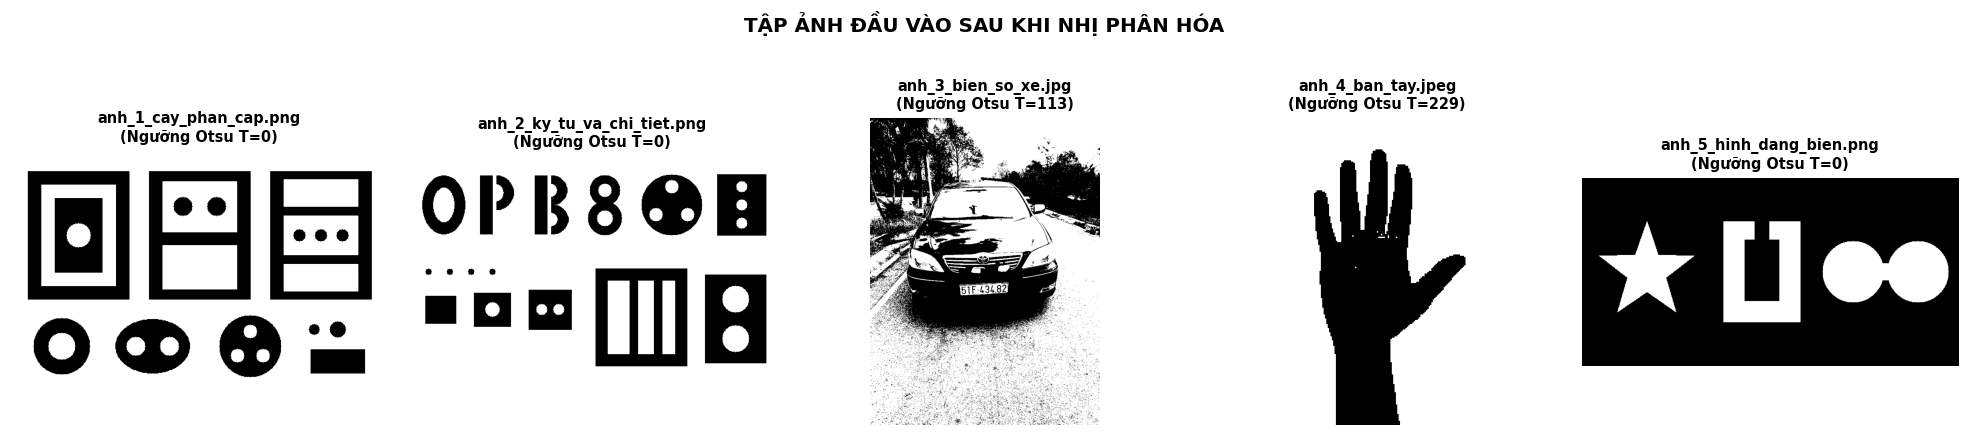

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import os
import glob
import shutil
import math
import warnings
warnings.filterwarnings('ignore')

# Cấu hình hiển thị Matplotlib
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# Hàm nhị phân hóa ảnh đầu vào (hỗ trợ cả ngưỡng cố định và Otsu tự động)
def nhi_phan_hoa(I_dau_vao, nguong=None, dao_nguoc=False):
    # Chuyển về ảnh xám nếu ảnh đầu vào là ảnh màu
    if len(I_dau_vao.shape) == 3:
        I_xam = cv2.cvtColor(I_dau_vao, cv2.COLOR_BGR2GRAY)
    else:
        I_xam = I_dau_vao.copy()
        
    kieu_nguong = cv2.THRESH_BINARY_INV if dao_nguoc else cv2.THRESH_BINARY
    if nguong is None:
        # Sử dụng thuật toán Otsu tự động tìm ngưỡng tối ưu
        gia_tri_t, I_np = cv2.threshold(I_xam, 0, 255, kieu_nguong + cv2.THRESH_OTSU)
    else:
        gia_tri_t, I_np = cv2.threshold(I_xam, nguong, 255, kieu_nguong)
        
    return I_np, gia_tri_t

# Khởi tạo thư mục tập ảnh thực nghiệm 'tap_anh'
os.makedirs('tap_anh', exist_ok=True)

# 1. Tạo Ảnh 1: Cấu trúc cây phân cấp đa tầng (Đen <-> Trắng lồng nhau đến độ sâu 4)
def tao_anh_1_cay_phan_cap():
    # Nền trắng ngoài cùng (255) - Độ sâu 0 (Root)
    img = np.full((360, 560), 255, dtype=np.uint8)
    
    # Khối Đen 1 (bên trái): có 1 con trắng -> trong con trắng có 1 con đen -> trong con đen có 1 con trắng
    cv2.rectangle(img, (25, 30), (175, 220), 0, -1)       # Vùng đen (1 con trắng)
    cv2.rectangle(img, (45, 50), (155, 200), 255, -1)     # Vùng trắng (1 con đen)
    cv2.rectangle(img, (65, 70), (135, 180), 0, -1)       # Vùng đen (1 con trắng)
    cv2.circle(img, (100, 125), 18, 255, -1)              # Vùng trắng trong cùng (0 con)
    
    # Khối Đen 2 (ở giữa): có 2 con trắng -> con trắng trên lại chứa 2 chấm đen
    cv2.rectangle(img, (205, 30), (355, 220), 0, -1)      # Vùng đen (2 con trắng)
    cv2.rectangle(img, (225, 45), (335, 120), 255, -1)    # Lỗ trắng 1 (chứa 2 con đen)
    cv2.circle(img, (255, 82), 14, 0, -1)                 # Chấm đen 1
    cv2.circle(img, (305, 82), 14, 0, -1)                 # Chấm đen 2
    cv2.rectangle(img, (225, 140), (335, 205), 255, -1)   # Lỗ trắng 2 (0 con)
    
    # Khối Đen 3 (bên phải): có 3 con trắng -> lỗ trắng giữa lại chứa 3 chấm đen
    cv2.rectangle(img, (385, 30), (535, 220), 0, -1)      # Vùng đen (3 con trắng)
    cv2.rectangle(img, (405, 42), (515, 82), 255, -1)     # Lỗ trắng 1 (0 con)
    cv2.rectangle(img, (405, 96), (515, 154), 255, -1)    # Lỗ trắng 2 (chứa 3 con đen)
    cv2.circle(img, (428, 125), 9, 0, -1)
    cv2.circle(img, (460, 125), 9, 0, -1)
    cv2.circle(img, (492, 125), 9, 0, -1)
    cv2.rectangle(img, (405, 168), (515, 208), 255, -1)   # Lỗ trắng 3 (0 con)
    
    # Hàng dưới: Các vật thể kích thước nhỏ, vừa, lớn có 0, 1, 2, 3 lỗ
    # Vòng đệm 1 lỗ (1 con)
    cv2.circle(img, (75, 290), 42, 0, -1)
    cv2.circle(img, (75, 290), 20, 255, -1)
    
    # Mặt nạ 2 lỗ (2 con)
    cv2.ellipse(img, (210, 290), (55, 40), 0, 0, 360, 0, -1)
    cv2.circle(img, (185, 290), 14, 255, -1)
    cv2.circle(img, (235, 290), 14, 255, -1)
    
    # Cúc áo 3 lỗ (3 con)
    cv2.circle(img, (355, 290), 46, 0, -1)
    cv2.circle(img, (355, 268), 10, 255, -1)
    cv2.circle(img, (336, 304), 10, 255, -1)
    cv2.circle(img, (374, 304), 10, 255, -1)
    
    # Các hạt nhỏ đặc (0 con)
    cv2.circle(img, (450, 265), 8, 0, -1)
    cv2.circle(img, (485, 265), 12, 0, -1)
    cv2.rectangle(img, (445, 295), (525, 330), 0, -1)
    
    cv2.imwrite('tap_anh/anh_1_cay_phan_cap.png', img)
    return img

# 2. Tạo Ảnh 2: Tập ký tự & Chi tiết kỹ thuật (Đa dạng diện tích, kích thước và số con 1, 2, 3)
def tao_anh_2_ky_tu_va_chi_tiet():
    img = np.full((380, 620), 255, dtype=np.uint8)
    
    # Nhóm 1 con (1 lỗ): Chữ O, P, A dạng hình học rõ nét
    # Chữ O
    cv2.ellipse(img, (65, 80), (35, 48), 0, 0, 360, 0, -1)
    cv2.ellipse(img, (65, 80), (17, 28), 0, 0, 360, 255, -1)
    
    # Chữ P
    cv2.rectangle(img, (125, 32), (145, 128), 0, -1)
    cv2.ellipse(img, (152, 60), (28, 28), 0, -90, 90, 0, -1)
    cv2.ellipse(img, (150, 60), (13, 14), 0, -90, 90, 255, -1)
    
    # Nhóm 2 con (2 lỗ): Chữ B và Số 8
    # Chữ B
    cv2.rectangle(img, (215, 32), (235, 128), 0, -1)
    cv2.ellipse(img, (242, 56), (26, 24), 0, -90, 90, 0, -1)
    cv2.ellipse(img, (242, 104), (28, 24), 0, -90, 90, 0, -1)
    cv2.ellipse(img, (240, 56), (11, 11), 0, -90, 90, 255, -1)
    cv2.ellipse(img, (240, 104), (12, 11), 0, -90, 90, 255, -1)
    
    # Số 8
    cv2.circle(img, (330, 56), 25, 0, -1)
    cv2.circle(img, (330, 102), 28, 0, -1)
    cv2.circle(img, (330, 56), 11, 255, -1)
    cv2.circle(img, (330, 102), 13, 255, -1)
    
    # Nhóm 3 con (3 lỗ): Mặt bích kỹ thuật 3 lỗ & Thanh gá 3 lỗ
    # Mặt bích tròn 3 lỗ
    cv2.circle(img, (440, 80), 50, 0, -1)
    cv2.circle(img, (440, 50), 11, 255, -1)
    cv2.circle(img, (414, 96), 11, 255, -1)
    cv2.circle(img, (466, 96), 11, 255, -1)
    
    # Thanh gá ngang 3 lỗ
    cv2.rectangle(img, (515, 30), (595, 130), 0, -1)
    cv2.circle(img, (555, 50), 9, 255, -1)
    cv2.circle(img, (555, 80), 9, 255, -1)
    cv2.circle(img, (555, 110), 9, 255, -1)
    
    # Hàng dưới: Các chi tiết có kích thước & diện tích khác nhau để lọc phạm vi
    # Chi tiết rất nhỏ (diện tích < 150 px)
    for x_pos in [40, 75, 110, 145]:
        cv2.circle(img, (x_pos, 190), 5, 0, -1)
        
    # Chi tiết vừa (diện tích từ 500 -> 2500 px)
    cv2.rectangle(img, (35, 230), (85, 275), 0, -1)                # Hộp đặc vừa
    cv2.rectangle(img, (115, 225), (175, 280), 0, -1)              # Hộp 1 lỗ vừa
    cv2.circle(img, (145, 252), 12, 255, -1)
    cv2.rectangle(img, (205, 220), (275, 285), 0, -1)              # Hộp 2 lỗ vừa
    cv2.circle(img, (226, 252), 9, 255, -1)
    cv2.circle(img, (254, 252), 9, 255, -1)
    
    # Chi tiết lớn (diện tích > 4000 px)
    cv2.rectangle(img, (315, 185), (465, 345), 0, -1)              # Khung lớn 3 lỗ
    cv2.rectangle(img, (335, 205), (370, 325), 255, -1)
    cv2.rectangle(img, (385, 205), (410, 325), 255, -1)
    cv2.rectangle(img, (425, 205), (445, 325), 255, -1)
    
    cv2.rectangle(img, (495, 195), (595, 340), 0, -1)              # Khung lớn 2 lỗ
    cv2.circle(img, (545, 235), 22, 255, -1)
    cv2.circle(img, (545, 300), 22, 255, -1)
    
    cv2.imwrite('tap_anh/anh_2_ky_tu_va_chi_tiet.png', img)
    return img

# 3. Copy ảnh thực tế Biển số xe và Bàn tay từ các lab trước
if os.path.exists('../lab05/bsx1.jpg'):
    shutil.copy2('../lab05/bsx1.jpg', 'tap_anh/anh_3_bien_so_xe.jpg')
if os.path.exists('../lab06/bantay.jpeg'):
    shutil.copy2('../lab06/bantay.jpeg', 'tap_anh/anh_4_ban_tay.jpeg')

# 4. Tạo Ảnh 5: Các hình dạng đường biên đặc trưng cho Phần 2 (Tỉ lệ d_ảnh / d_biên)
def tao_anh_5_hinh_dang_bien():
    img = np.zeros((320, 640), dtype=np.uint8)
    
    # Hình 1: Ngôi sao 5 cánh (các đỉnh nhọn và khe lõm có tỉ lệ d_ảnh / d_biên rất nhỏ)
    cx, cy, R_out, R_in = 110, 160, 85, 34
    pts_star = []
    for k in range(10):
        angle = -math.pi / 2 + k * math.pi / 5
        r = R_out if k % 2 == 0 else R_in
        pts_star.append([int(cx + r * math.cos(angle)), int(cy + r * math.sin(angle))])
    cv2.fillPoly(img, [np.array(pts_star, dtype=np.int32)], 255)
    
    # Hình 2: Hình chữ U / Móng ngựa (2 nhánh tiến lại gần nhau: d_ảnh rất nhỏ nhưng d_biên đi vòng qua đáy chữ U rất dài)
    cv2.rectangle(img, (240, 75), (275, 245), 255, -1)
    cv2.rectangle(img, (335, 75), (370, 245), 255, -1)
    cv2.rectangle(img, (240, 210), (370, 245), 255, -1)
    # Thêm mấu khép nhẹ ở miệng chữ U để tạo khe hẹp rõ rệt
    cv2.rectangle(img, (275, 75), (292, 105), 255, -1)
    cv2.rectangle(img, (318, 75), (335, 105), 255, -1)
    
    # Hình 3: Hình quả tạ thắt cổ chai (Dumbbell / Bottleneck)
    cv2.circle(img, (460, 160), 52, 255, -1)
    cv2.circle(img, (570, 160), 52, 255, -1)
    cv2.rectangle(img, (460, 146), (570, 174), 255, -1)
    
    cv2.imwrite('tap_anh/anh_5_hinh_dang_bien.png', img)
    return img

img1 = tao_anh_1_cay_phan_cap()
img2 = tao_anh_2_ky_tu_va_chi_tiet()
img5 = tao_anh_5_hinh_dang_bien()

danh_sach_anh = sorted(glob.glob('tap_anh/*'))
print("Đã chuẩn bị hoàn tất tập ảnh thực nghiệm trong thư mục 'tap_anh/':")
for p in danh_sach_anh:
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    print(f" - {os.path.basename(p):30s} | Kích thước: {im.shape[1]}x{im.shape[0]}")

# Hiển thị tổng quan tập ảnh sau khi nhị phân hóa
fig, axes = plt.subplots(1, len(danh_sach_anh), figsize=(18, 3.8))
for idx, p in enumerate(danh_sach_anh):
    im_goc = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    im_np, t_val = nhi_phan_hoa(im_goc)
    axes[idx].imshow(im_np, cmap='gray')
    axes[idx].set_title(f"{os.path.basename(p)}\n(Ngưỡng Otsu T={t_val:.0f})", fontsize=9.5, fontweight='bold')
    axes[idx].axis('off')
plt.suptitle("TẬP ẢNH ĐẦU VÀO SAU KHI NHỊ PHÂN HÓA", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

---
## PHẦN 1: XÂY DỰNG CẤU TRÚC CÂY BAO HÀM CÁC VÙNG NHỊ PHÂN (ĐEN $\leftrightarrow$ TRẮNG)

### 1.1. Cơ sở lý thuyết và nguyên lý xây dựng cây phân cấp vùng nhị phân
Trên một ảnh nhị phân $I(x, y) \in \{0, 255\}$ (trong đó `0` là điểm ảnh **Đen** và `255` là điểm ảnh **Trắng**), toàn bộ mặt phẳng ảnh được phân hoạch thành các **miền liên thông** (connected regions) rời nhau của các điểm đen và các điểm trắng.

Để định nghĩa chặt chẽ quan hệ **"vùng này nằm trong vùng kia"** (định lý đường cong kín Jordan rời rạc, tránh nghịch lý giao cắt đường chéo):
- Các vùng cùng màu được gom nhóm theo lân cận liên thông (sử dụng **8-liên thông** cho vùng Đen `0` và **4-liên thông** cho vùng Trắng `255`, hoặc ngược lại).
- Để có một nút gốc (Root) duy nhất đại diện cho toàn bộ khung nền bao quanh ảnh, ta bọc thêm một viền 1 pixel (màu nền ngoài cùng, mặc định là Trắng `255`) quanh biên ảnh trước khi duyệt, sau đó quy chiếu lại tọa độ gốc.

#### Quy tắc xác định Cha – Con (Containment Hierarchy):
1. **Đánh nhãn toàn bộ miền liên thông (Đen và Trắng) bằng BFS:**
   Mỗi miền liên thông $R_k$ ($k = 1, 2, \dots, M$) mang một màu duy nhất (`0` - Đen hoặc `255` - Trắng), có:
   - **Diện tích thực tế (`area`):** Số lượng điểm ảnh thuộc miền $R_k$.
   - **Hộp giới hạn (`bbox`):** $(x_{\min}, y_{\min}, w, h)$, suy ra kích thước chiều rộng $w$, chiều cao $h$, và diện tích hộp bao $w \times h$.
   - **Điểm cực trị trên-trái (`top_left_pixel`):** Điểm $(x_0, y_0) \in R_k$ có tung độ $y_0$ nhỏ nhất, và trong các điểm có cùng $y_0$ nhỏ nhất thì lấy hoành độ $x_0$ nhỏ nhất.
2. **Xác định nút cha trực tiếp (Immediate Enclosing Parent) trong thời gian $O(1)$ cho mỗi vùng:**
   - Do $(x_0, y_0)$ là điểm cao nhất và trái nhất của vùng $R_k$ (với mọi vùng $R_k$ không phải là gốc ngoài cùng), điểm ảnh nằm ngay phía trên nó là $(x_0, y_0 - 1)$ (hoặc bên trái $(x_0 - 1, y_0)$) **chắc chắn không thuộc $R_k$** và **chắc chắn thuộc miền liên thông bao quanh trực tiếp bên ngoài biên ngoài của $R_k$**.
   - Nhờ tính chất phân hoạch nhị phân, miền cha trực tiếp của một **vùng Đen (`0`)** luôn là một **vùng Trắng (`255`)**, và miền cha trực tiếp của một **vùng Trắng (`255`)** luôn là một **vùng Đen (`0`)**.
   - Cây thu được là **cây phân cấp xen kẽ Đen $\leftrightarrow$ Trắng**:
     $$\text{Gốc Trắng (Nền)} \longrightarrow \text{Vùng Đen (Vật thể)} \longrightarrow \text{Vùng Trắng (Lỗ)} \longrightarrow \text{Vùng Đen (Đảo trong lỗ)} \longrightarrow \dots$$

In [2]:
# 1.2. Cài đặt cấu trúc dữ liệu Nút vùng (RegionNode) và Thuật toán BFS xây dựng Cây bao hàm

class RegionNode:
    """Biểu diễn một nút (một miền liên thông Đen hoặc Trắng) trong cây phân cấp."""
    def __init__(self, node_id, mau):
        self.id = node_id
        self.mau = int(mau)  # 0 (Đen) hoặc 255 (Trắng)
        self.ten_mau = "Đen (0)" if self.mau == 0 else "Trắng (255)"
        self.dien_tich = 0   # Số điểm ảnh thực tế (Area) trong khung ảnh gốc
        self.x_min = 10**9
        self.y_min = 10**9
        self.x_max = -1
        self.y_max = -1
        self.tong_x = 0
        self.tong_y = 0
        self.diem_cuc_tri_pad = None  # (y_pad, x_pad) nhỏ nhất theo thứ tự từ điển
        self.cha_id = None
        self.con_ids = []
        self.do_sau = 0

    @property
    def chieu_rong(self):
        return max(0, self.x_max - self.x_min + 1) if self.x_max >= 0 else 0

    @property
    def chieu_cao(self):
        return max(0, self.y_max - self.y_min + 1) if self.y_max >= 0 else 0

    @property
    def kich_thuoc_hop(self):
        """Diện tích hộp giới hạn (Bounding Box Size = W * H)."""
        return self.chieu_rong * self.chieu_cao

    @property
    def duong_cheo_hop(self):
        """Độ dài đường chéo hộp giới hạn."""
        return math.hypot(self.chieu_rong, self.chieu_cao)

    @property
    def tam_vung(self):
        if self.dien_tich > 0:
            return (self.tong_x / self.dien_tich, self.tong_y / self.dien_tich)
        return ((self.x_min + self.x_max) / 2.0, (self.y_min + self.y_max) / 2.0)

    @property
    def so_con(self):
        return len(self.con_ids)


def xay_dung_cay_vung_nhi_phan(I_np, mau_nen_goc=255):
    """
    Xây dựng cây phân cấp các vùng liên thông Đen (0) và Trắng (255).
    - Nếu vùng Đen chứa vùng Trắng -> vùng Trắng là con của vùng Đen.
    - Nếu vùng Trắng chứa vùng Đen -> vùng Đen là con của vùng Trắng.
    
    Trả về:
    - danh_sach_nut: dict {node_id: RegionNode}
    - ban_do_nhan: ma trận nhãn (H, W) ứng với tọa độ ảnh gốc
    - goc_id: ID của nút gốc ngoài cùng (luôn là 1)
    """
    H, W = I_np.shape
    # Bọc 1 lớp viền 1-pixel màu nền ngoài cùng để tạo nút gốc (Root) bao trọn toàn ảnh
    I_pad = np.full((H + 2, W + 2), mau_nen_goc, dtype=np.uint8)
    I_pad[1:H+1, 1:W+1] = I_np

    H_p, W_p = I_pad.shape
    nhan_pad = np.zeros((H_p, W_p), dtype=np.int32)
    danh_sach_nut = {}
    so_vung = 0

    # Lân cận 4-liên thông (cho vùng Trắng) và 8-liên thông (cho vùng Đen)
    # để đảm bảo tính chất đường cong kín Jordan trên lưới điểm ảnh rời rạc
    lan_can_4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    lan_can_8 = [(-1, -1), (-1, 0), (-1, 1),
                 (0, -1),           (0, 1),
                 (1, -1),  (1, 0),  (1, 1)]

    # Bước 1: Duyệt từ trên xuống dưới, từ trái sang phải và loang BFS cho cả vùng Đen lẫn Trắng
    for r in range(H_p):
        for c in range(W_p):
            if nhan_pad[r, c] == 0:
                so_vung += 1
                mau_hien_tai = int(I_pad[r, c])
                nut = RegionNode(so_vung, mau_hien_tai)
                # Điểm (r, c) đầu tiên gặp khi quét theo hàng chính là điểm cực trị trên-trái
                nut.diem_cuc_tri_pad = (r, c)

                lan_can = lan_can_8 if mau_hien_tai == 0 else lan_can_4
                hang_doi = deque([(r, c)])
                nhan_pad[r, c] = so_vung

                while hang_doi:
                    cy, cx = hang_doi.popleft()
                    # Chỉ tính diện tích và bounding box cho các điểm thực sự nằm trong khung ảnh gốc [1..H, 1..W]
                    if 1 <= cy <= H and 1 <= cx <= W:
                        y_goc = cy - 1
                        x_goc = cx - 1
                        nut.dien_tich += 1
                        nut.tong_x += x_goc
                        nut.tong_y += y_goc
                        if x_goc < nut.x_min: nut.x_min = x_goc
                        if x_goc > nut.x_max: nut.x_max = x_goc
                        if y_goc < nut.y_min: nut.y_min = y_goc
                        if y_goc > nut.y_max: nut.y_max = y_goc

                    for dy, dx in lan_can:
                        ny, nx = cy + dy, cx + dx
                        if 0 <= ny < H_p and 0 <= nx < W_p:
                            if nhan_pad[ny, nx] == 0 and I_pad[ny, nx] == mau_hien_tai:
                                nhan_pad[ny, nx] = so_vung
                                hang_doi.append((ny, nx))

                danh_sach_nut[so_vung] = nut

    # Bước 2: Thiết lập quan hệ Cha - Con trực tiếp từ điểm cực trị trên-trái của mỗi vùng
    goc_id = 1
    for node_id, nut in danh_sach_nut.items():
        if node_id == goc_id:
            nut.cha_id = None
            nut.do_sau = 0
        else:
            r0, c0 = nut.diem_cuc_tri_pad
            # Điểm ngay phía trên (r0 - 1, c0) chắc chắn thuộc miền bao hàm trực tiếp của vùng hiện tại
            cha_id = int(nhan_pad[r0 - 1, c0])
            nut.cha_id = cha_id
            danh_sach_nut[cha_id].con_ids.append(node_id)

    # Bước 3: Cập nhật độ sâu (depth) trên cây theo BFS từ nút gốc
    q_cay = deque([goc_id])
    while q_cay:
        u_id = q_cay.popleft()
        u_nut = danh_sach_nut[u_id]
        for v_id in u_nut.con_ids:
            danh_sach_nut[v_id].do_sau = u_nut.do_sau + 1
            q_cay.append(v_id)

    ban_do_nhan = nhan_pad[1:H+1, 1:W+1].copy()
    return danh_sach_nut, ban_do_nhan, goc_id


def in_cay_phan_cap(danh_sach_nut, goc_id=1, gioi_han_dong=40):
    """In cấu trúc cây bao hàm Đen <-> Trắng dạng nhánh trực quan."""
    cac_dong = []
    def duyet_dfs(u_id, tien_to="", la_cuoi=True):
        nut = danh_sach_nut[u_id]
        nhanh = "└── " if la_cuoi else "├── "
        if u_id == goc_id:
            chuoi_nut = (f"[Nút #{nut.id} - GỐC] Màu: {nut.ten_mau} | Độ sâu: {nut.do_sau} | "
                         f"Diện tích: {nut.dien_tich} px | Số con: {nut.so_con}")
            cac_dong.append(chuoi_nut)
        else:
            chuoi_nut = (f"{tien_to}{nhanh}[Nút #{nut.id:02d}] Màu: {nut.ten_mau:11s} | "
                         f"Độ sâu: {nut.do_sau} | Diện tích: {nut.dien_tich:5d} px | "
                         f"BBox: {nut.chieu_rong}x{nut.chieu_cao} ({nut.kich_thuoc_hop} px²) | "
                         f"Số con: {nut.so_con}")
            cac_dong.append(chuoi_nut)

        tien_to_moi = "" if u_id == goc_id else tien_to + ("    " if la_cuoi else "│   ")
        for idx, con_id in enumerate(nut.con_ids):
            duyet_dfs(con_id, tien_to_moi, idx == len(nut.con_ids) - 1)

    duyet_dfs(goc_id)
    for d in cac_dong[:gioi_han_dong]:
        print(d)
    if len(cac_dong) > gioi_han_dong:
        print(f"... (Còn {len(cac_dong) - gioi_han_dong} nút khác trong cây)")


def ve_so_do_cay_truc_quan(ax, danh_sach_nut, goc_id=1, tieu_de="Sơ đồ cấu trúc cây Đen <-> Trắng"):
    """Vẽ sơ đồ cây phân cấp (Hierarchy Tree Graph) lên trục Matplotlib."""
    # Tính vị trí ngang (x) cho từng nút theo thứ tự duyệt lá
    vi_tri_x = {}
    dem_la = [0]

    def gan_toa_do_x(u_id):
        con_list = danh_sach_nut[u_id].con_ids
        if not con_list:
            vi_tri_x[u_id] = float(dem_la[0])
            dem_la[0] += 1
        else:
            for c_id in con_list:
                gan_toa_do_x(c_id)
            vi_tri_x[u_id] = np.mean([vi_tri_x[c_id] for c_id in con_list])

    gan_toa_do_x(goc_id)
    max_depth = max(n.do_sau for n in danh_sach_nut.values())

    # Vẽ các cạnh nối Cha -> Con
    for u_id, nut in danh_sach_nut.items():
        x_u = vi_tri_x[u_id]
        y_u = -nut.do_sau
        for v_id in nut.con_ids:
            x_v = vi_tri_x[v_id]
            y_v = -danh_sach_nut[v_id].do_sau
            ax.plot([x_u, x_v], [y_u, y_v], color='#64748B', linewidth=1.4, zorder=1)

    # Vẽ các nút: Nút Đen tô màu đen chữ trắng, Nút Trắng tô màu trắng viền đen chữ đen
    for u_id, nut in danh_sach_nut.items():
        x_u = vi_tri_x[u_id]
        y_u = -nut.do_sau
        la_den = (nut.mau == 0)
        mau_nen = '#1E293B' if la_den else '#FFFFFF'
        mau_chu = '#FFFFFF' if la_den else '#0F172A'
        mau_vien = '#38BDF8' if nut.so_con > 0 else '#475569'
        ax.scatter([x_u], [y_u], s=420, facecolor=mau_nen, edgecolor=mau_vien, linewidth=2.0, zorder=3)
        ax.text(x_u, y_u, f"#{u_id}\n({nut.so_con}c)", ha='center', va='center',
                fontsize=7.5, fontweight='bold', color=mau_chu, zorder=4)

    ax.set_title(tieu_de, fontsize=11, fontweight='bold')
    ax.set_yticks([-d for d in range(max_depth + 1)])
    ax.set_yticklabels([f"Tầng {d} ({'Trắng' if d % 2 == 0 else 'Đen'})" for d in range(max_depth + 1)], fontsize=9)
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.margins(x=0.08, y=0.15)

KẾT QUẢ XÂY DỰNG CÂY VÙNG NHỊ PHÂN TRÊN 'anh_1_cay_phan_cap.png' (Tổng số nút: 29)
[Nút #1 - GỐC] Màu: Trắng (255) | Độ sâu: 0 | Diện tích: 92314 px | Số con: 9
├── [Nút #02] Màu: Đen (0)     | Độ sâu: 1 | Diện tích: 12080 px | BBox: 151x191 (28841 px²) | Số con: 1
│   └── [Nút #07] Màu: Trắng (255) | Độ sâu: 2 | Diện tích:  8880 px | BBox: 111x151 (16761 px²) | Số con: 1
│       └── [Nút #10] Màu: Đen (0)     | Độ sâu: 3 | Diện tích:  6872 px | BBox: 71x111 (7881 px²) | Số con: 1
│           └── [Nút #12] Màu: Trắng (255) | Độ sâu: 4 | Diện tích:  1009 px | BBox: 37x37 (1369 px²) | Số con: 0
├── [Nút #03] Màu: Đen (0)     | Độ sâu: 1 | Diện tích: 13079 px | BBox: 151x191 (28841 px²) | Số con: 2
│   ├── [Nút #06] Màu: Trắng (255) | Độ sâu: 2 | Diện tích:  7210 px | BBox: 111x76 (8436 px²) | Số con: 2
│   │   ├── [Nút #08] Màu: Đen (0)     | Độ sâu: 3 | Diện tích:   613 px | BBox: 29x29 (841 px²) | Số con: 0
│   │   └── [Nút #09] Màu: Đen (0)     | Độ sâu: 3 | Diện tích:   613 px | BBox

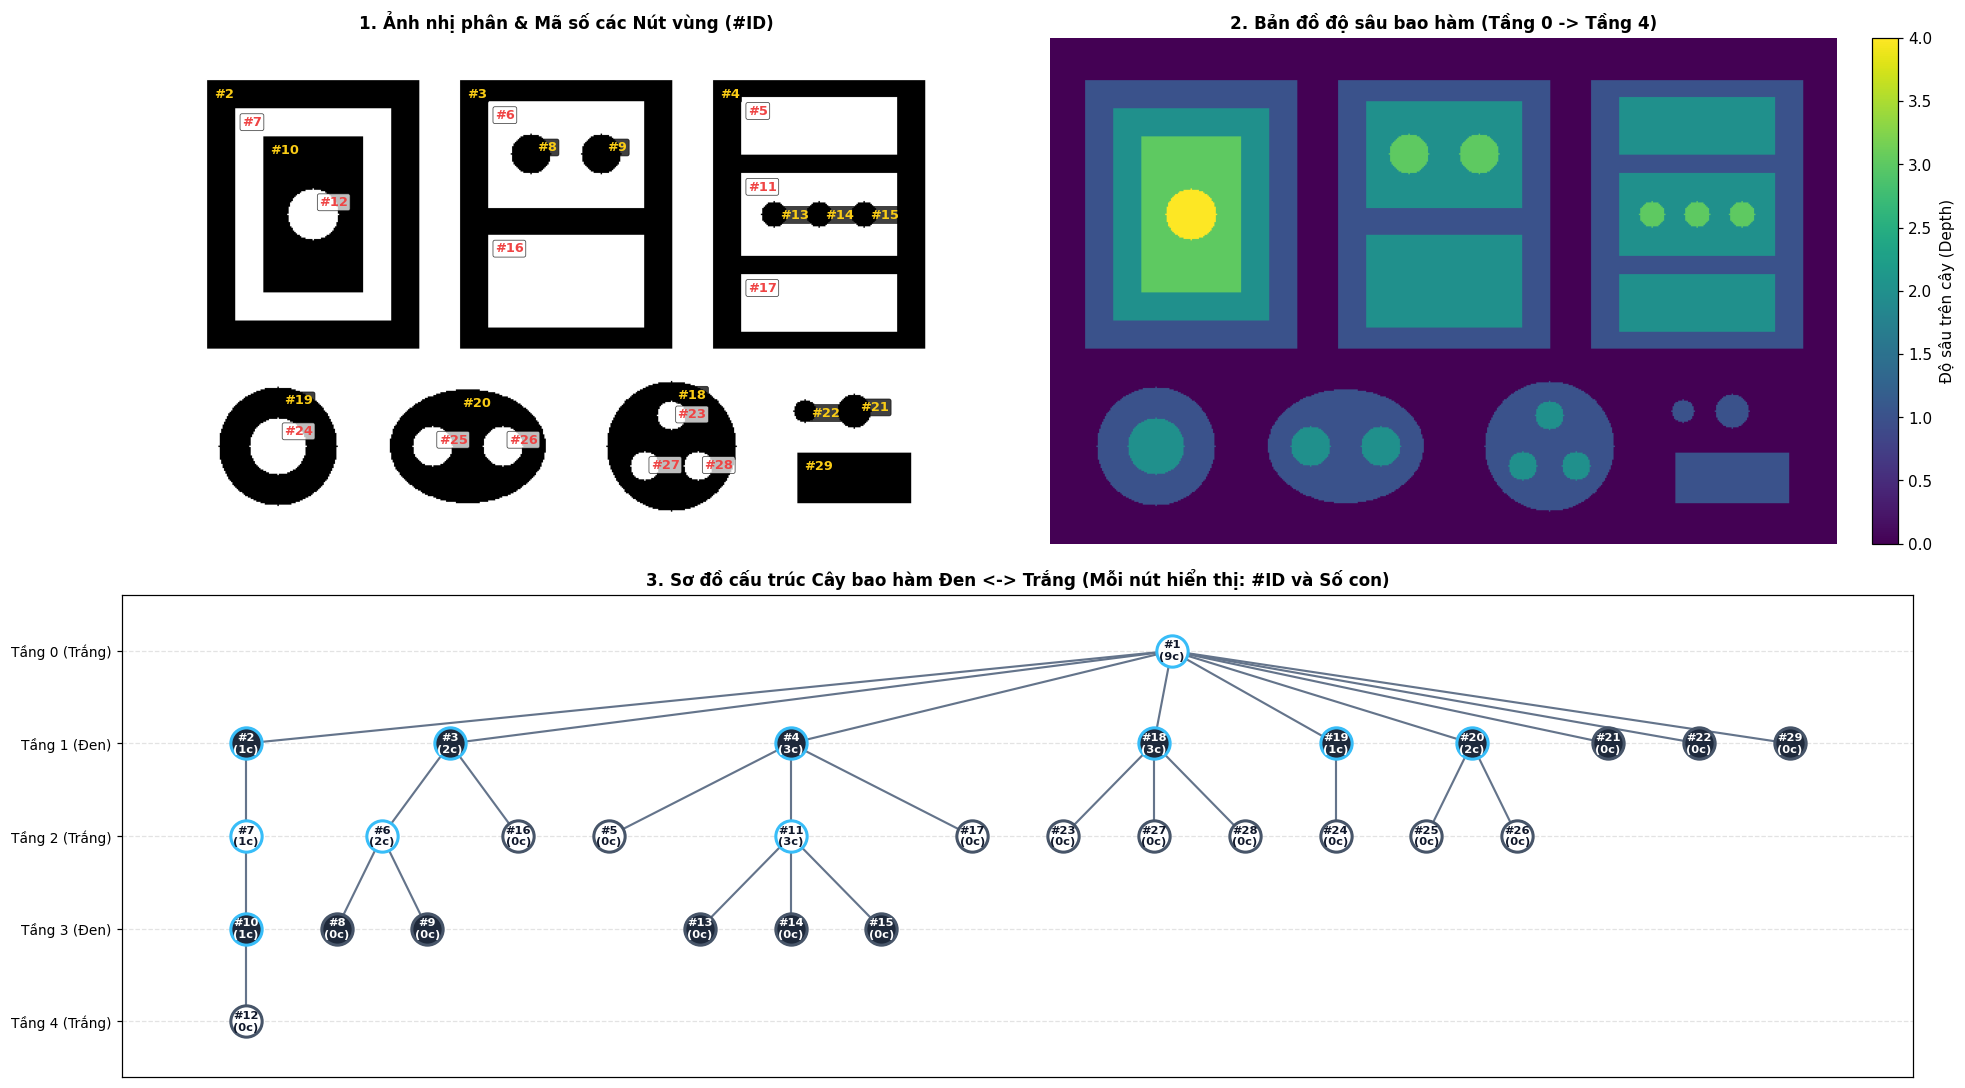

In [3]:
# 1.3. Thực nghiệm xây dựng và trực quan hóa cây phân cấp trên ảnh đa tầng (Ảnh 1)

I_goc_1 = cv2.imread('tap_anh/anh_1_cay_phan_cap.png', cv2.IMREAD_GRAYSCALE)
I_np_1, nguong_1 = nhi_phan_hoa(I_goc_1)

danh_sach_nut_1, ban_do_nhan_1, goc_id_1 = xay_dung_cay_vung_nhi_phan(I_np_1, mau_nen_goc=255)

print("=" * 95)
print(f"KẾT QUẢ XÂY DỰNG CÂY VÙNG NHỊ PHÂN TRÊN 'anh_1_cay_phan_cap.png' (Tổng số nút: {len(danh_sach_nut_1)})")
print("=" * 95)
in_cay_phan_cap(danh_sach_nut_1, goc_id_1)

# Tạo bản đồ độ sâu (Depth Map) để thấy rõ các tầng lồng nhau Đen <-> Trắng
ban_do_do_sau_1 = np.zeros_like(ban_do_nhan_1, dtype=np.int32)
for nid, nut in danh_sach_nut_1.items():
    ban_do_do_sau_1[ban_do_nhan_1 == nid] = nut.do_sau

# Minh họa trực quan: (1) Ảnh nhị phân kèm nhãn ID, (2) Bản đồ độ sâu của cây, (3) Sơ đồ cây
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.05, 1.0])

ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(I_np_1, cmap='gray')
for nid, nut in danh_sach_nut_1.items():
    if nid == goc_id_1:
        continue
    # Đặt nhãn tại điểm cực trị trên-trái hoặc tâm để không đè lên lỗ con
    ry, rx = nut.diem_cuc_tri_pad[0] - 1, nut.diem_cuc_tri_pad[1] - 1
    mau_nhan = '#FACC15' if nut.mau == 0 else '#EF4444'
    ax1.text(rx + 4, ry + 12, f"#{nid}", color=mau_nhan, fontsize=8.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.15', facecolor='black' if nut.mau==0 else 'white', alpha=0.75, lw=0.5))
ax1.set_title("1. Ảnh nhị phân & Mã số các Nút vùng (#ID)", fontsize=11, fontweight='bold')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 1])
im_depth = ax2.imshow(ban_do_do_sau_1, cmap='viridis')
plt.colorbar(im_depth, ax=ax2, fraction=0.046, pad=0.04, label='Độ sâu trên cây (Depth)')
ax2.set_title("2. Bản đồ độ sâu bao hàm (Tầng 0 -> Tầng 4)", fontsize=11, fontweight='bold')
ax2.axis('off')

ax3 = fig.add_subplot(gs[1, :])
ve_so_do_cay_truc_quan(ax3, danh_sach_nut_1, goc_id_1,
                       tieu_de="3. Sơ đồ cấu trúc Cây bao hàm Đen <-> Trắng (Mỗi nút hiển thị: #ID và Số con)")

plt.tight_layout()
plt.show()

---
### 1.4. Truy vấn trên cây phân cấp vùng nhị phân

Từ cấu trúc cây vùng nhị phân $T = (V, E)$ đã xây dựng, mỗi nút $u \in V$ lưu trữ đầy đủ thông tin hình học và quan hệ phân cấp:
1. **Lọc theo kích thước (`size`) và diện tích (`area`) trong phạm vi cho trước:**
   - **Diện tích thực tế (`dien_tich`):** $A(u) = |R_u|$ (tổng số pixel thuộc miền liên thông $u$).
   - **Kích thước (`kich_thuoc`):** Có thể xét theo diện tích hộp giới hạn $S_{\text{box}}(u) = W(u) \times H(u)$, hoặc kích thước chiều rộng $W(u) \in [W_{\min}, W_{\max}]$ và chiều cao $H(u) \in [H_{\min}, H_{\max}]$.
   - Điều kiện lọc:
     $$A_{\min} \le A(u) \le A_{\max} \quad \text{và} \quad S_{\min} \le S_{\text{box}}(u) \le S_{\max}$$
2. **Lọc các vùng có 1 con, 2 con, 3 con (`so_con` $\in \{1, 2, 3\}$):**
   - Số con của nút $u$ chính là bậc ra $\deg^+(u) = |\text{con\_ids}(u)|$, tức là **số vùng khác màu nằm trực tiếp bên trong $u$**:
     - Nếu $u$ là **vùng Đen (`0`)**: `so_con = k` nghĩa là vật thể màu đen đó có đúng **$k$ lỗ thủng màu trắng** bên trong (ví dụ: chữ `O, P, A, D, 0, 4, 6, 9` có 1 con; chữ `B, 8` có 2 con; mặt bích/cúc áo 3 lỗ có 3 con).
     - Nếu $u$ là **vùng Trắng (`255`)**: `so_con = k` nghĩa là khoang/lỗ trắng đó chứa trực tiếp **$k$ đảo màu đen** bên trong (ví dụ: khung biển số xe màu trắng chứa các ký tự đen bên trong, hoặc lỗ trắng trong Ảnh 1 chứa 1, 2, 3 chấm đen).

THỰC NGHIỆM 1A: LỌC VÙNG THEO KÍCH THƯỚC VÀ DIỆN TÍCH TRÊN 'anh_2_ky_tu_va_chi_tiet.png'

+ Nhóm 1: Chi tiết & Lỗ nhỏ (Diện tích: 50 - 700 px | BBox: 60 - 900 px²) -> Tìm thấy 15 vùng:
   - Nút #10 (Trắng (255)) | Diện tích:   377 px | Kích thước BBox:  23x23  =    529 px² | Số con: 0
   - Nút #11 (Trắng (255)) | Diện tích:   253 px | Kích thước BBox:  19x19  =    361 px² | Số con: 0
   - Nút #12 (Trắng (255)) | Diện tích:   377 px | Kích thước BBox:  23x23  =    529 px² | Số con: 0
   - Nút #14 (Trắng (255)) | Diện tích:   253 px | Kích thước BBox:  19x19  =    361 px² | Số con: 0
   - Nút #15 (Trắng (255)) | Diện tích:   377 px | Kích thước BBox:  23x23  =    529 px² | Số con: 0
   - Nút #16 (Trắng (255)) | Diện tích:   377 px | Kích thước BBox:  23x23  =    529 px² | Số con: 0
   - Nút #17 (Trắng (255)) | Diện tích:   529 px | Kích thước BBox:  27x27  =    729 px² | Số con: 0
   - Nút #18 (Trắng (255)) | Diện tích:   253 px | Kích thước BBox:  19x19  =    361 px² | Số con: 0
   - Nú

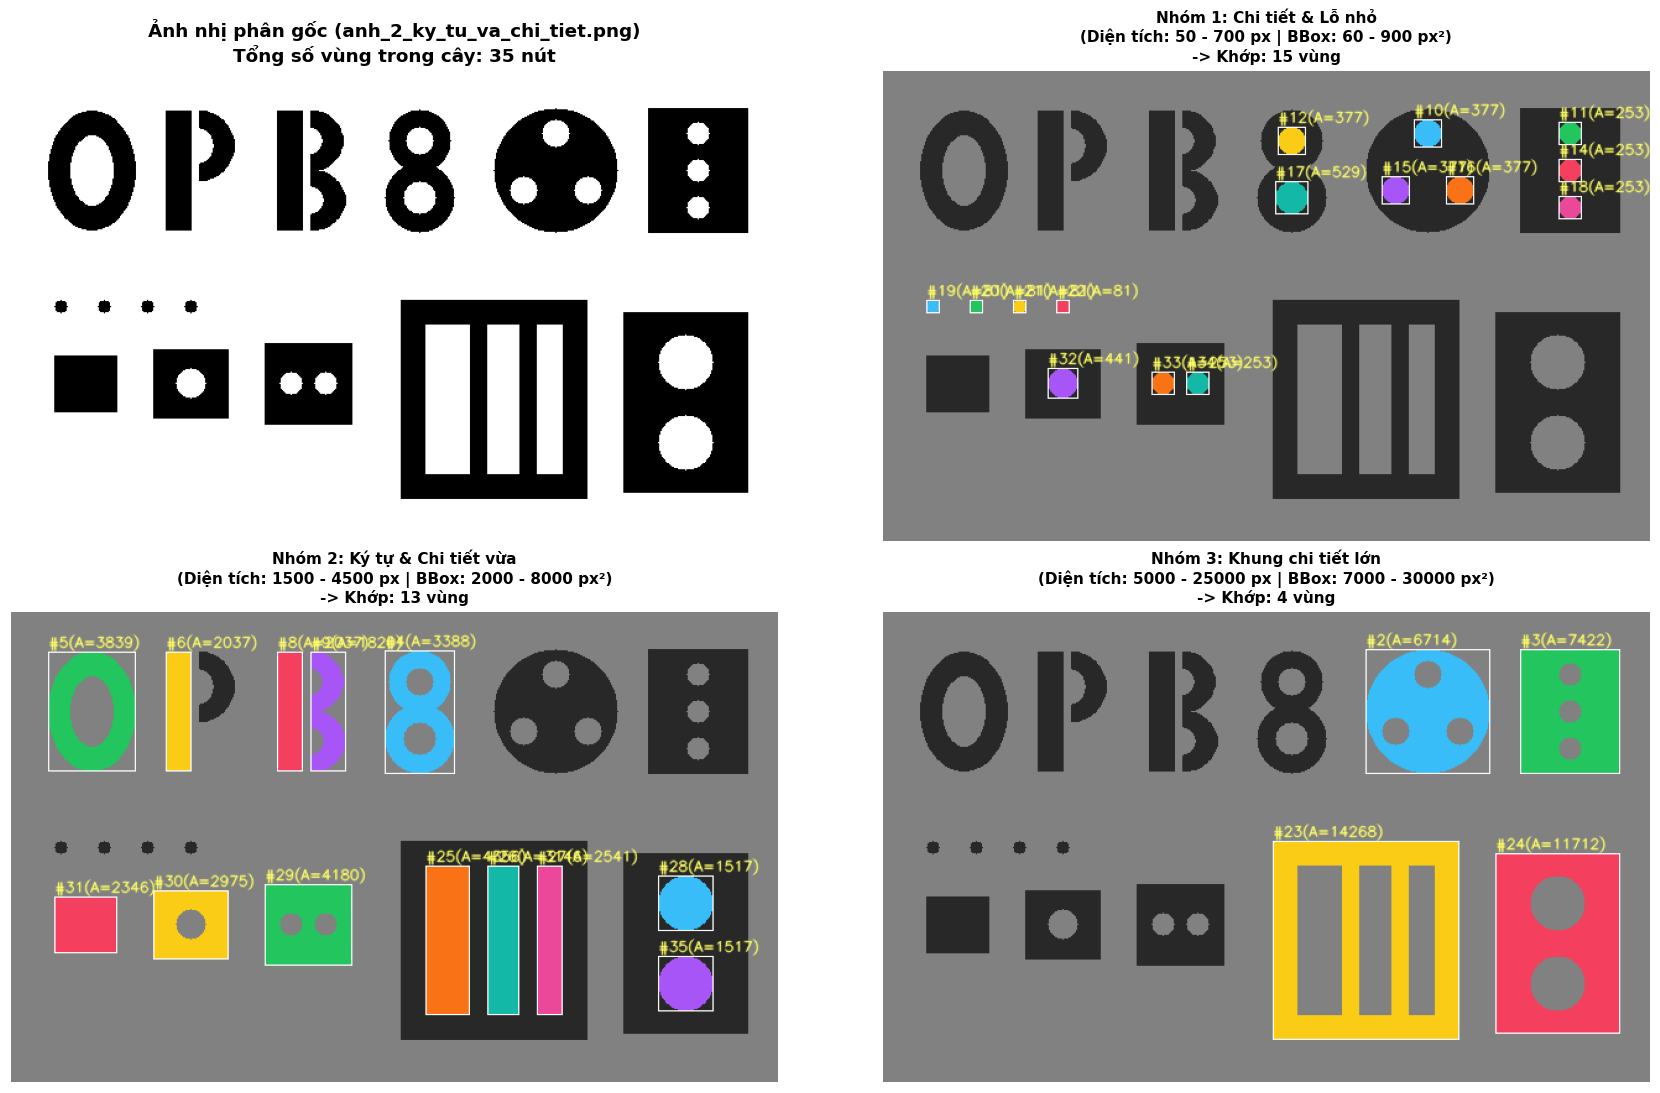

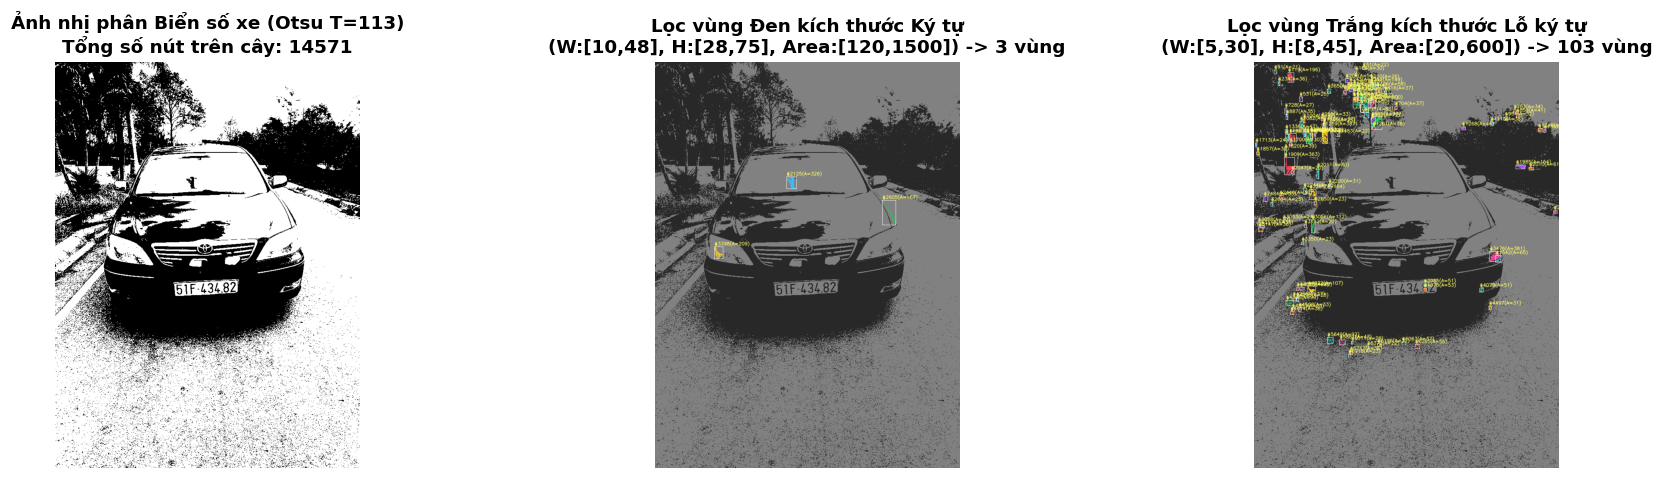

In [4]:
# 1.5. Thực nghiệm 1: Hiển thị các vùng có Kích thước và Diện tích trong phạm vi cho trước

def loc_vung_theo_kich_thuoc_va_dien_tich(danh_sach_nut, goc_id,
                                          dien_tich_min=0, dien_tich_max=10**9,
                                          kich_thuoc_hop_min=0, kich_thuoc_hop_max=10**9,
                                          rong_min=0, rong_max=10**9,
                                          cao_min=0, cao_max=10**9,
                                          mau_chon=None, bo_qua_goc=True):
    """
    Lọc các nút trong cây thỏa mãn đồng thời phạm vi Diện tích (số điểm ảnh)
    và Kích thước (diện tích hộp bao W*H, chiều rộng W, chiều cao H).
    """
    ket_qua = []
    for nid, nut in danh_sach_nut.items():
        if bo_qua_goc and nid == goc_id:
            continue
        if mau_chon is not None and nut.mau != mau_chon:
            continue
        if not (dien_tich_min <= nut.dien_tich <= dien_tich_max):
            continue
        if not (kich_thuoc_hop_min <= nut.kich_thuoc_hop <= kich_thuoc_hop_max):
            continue
        if not (rong_min <= nut.chieu_rong <= rong_max):
            continue
        if not (cao_min <= nut.chieu_cao <= cao_max):
            continue
        ket_qua.append(nut)
    return ket_qua


def tao_anh_minh_hoa_cac_vung(I_np, ban_do_nhan, cac_nut_chon, ve_bbox=True):
    """Tô màu nổi bật các vùng được chọn trên nền ảnh nhị phân làm mờ."""
    H, W = I_np.shape
    # Nền xám mờ để nổi bật vùng được lọc
    anh_hien_thi = np.stack([I_np, I_np, I_np], axis=-1).astype(np.float32) * 0.35 + 40
    anh_hien_thi = np.clip(anh_hien_thi, 0, 255).astype(np.uint8)

    bang_mau = [
        (56, 189, 248), (34, 197, 94), (250, 204, 21), (244, 63, 94),
        (168, 85, 247), (249, 115, 22), (20, 184, 166), (236, 72, 153)
    ]

    for idx, nut in enumerate(cac_nut_chon):
        mau_rgb = bang_mau[idx % len(bang_mau)]
        anh_hien_thi[ban_do_nhan == nut.id] = mau_rgb
        if ve_bbox and nut.x_max >= 0:
            cv2.rectangle(anh_hien_thi, (nut.x_min, nut.y_min), (nut.x_max, nut.y_max), (255, 255, 255), 1)
            cv2.putText(anh_hien_thi, f"#{nut.id}(A={nut.dien_tich})",
                        (max(0, nut.x_min), max(12, nut.y_min - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.38, (255, 255, 100), 1, cv2.LINE_AA)
    return anh_hien_thi


# --- A. Thử nghiệm trên Ảnh 2 (Ký tự & Chi tiết kỹ thuật) với 3 khoảng Kích thước & Diện tích ---
I_goc_2 = cv2.imread('tap_anh/anh_2_ky_tu_va_chi_tiet.png', cv2.IMREAD_GRAYSCALE)
I_np_2, _ = nhi_phan_hoa(I_goc_2)
nut_2, nhan_2, goc_2 = xay_dung_cay_vung_nhi_phan(I_np_2)

cac_cau_hinh_loc_anh2 = [
    {
        "ten": "Nhóm 1: Chi tiết & Lỗ nhỏ\n(Diện tích: 50 - 700 px | BBox: 60 - 900 px²)",
        "params": dict(dien_tich_min=50, dien_tich_max=700, kich_thuoc_hop_min=60, kich_thuoc_hop_max=900)
    },
    {
        "ten": "Nhóm 2: Ký tự & Chi tiết vừa\n(Diện tích: 1500 - 4500 px | BBox: 2000 - 8000 px²)",
        "params": dict(dien_tich_min=1500, dien_tich_max=4500, kich_thuoc_hop_min=2000, kich_thuoc_hop_max=8000)
    },
    {
        "ten": "Nhóm 3: Khung chi tiết lớn\n(Diện tích: 5000 - 25000 px | BBox: 7000 - 30000 px²)",
        "params": dict(dien_tich_min=5000, dien_tich_max=25000, kich_thuoc_hop_min=7000, kich_thuoc_hop_max=30000)
    }
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
axes[0].imshow(I_np_2, cmap='gray')
axes[0].set_title(f"Ảnh nhị phân gốc (anh_2_ky_tu_va_chi_tiet.png)\nTổng số vùng trong cây: {len(nut_2)} nút", fontweight='bold')
axes[0].axis('off')

print("=" * 95)
print("THỰC NGHIỆM 1A: LỌC VÙNG THEO KÍCH THƯỚC VÀ DIỆN TÍCH TRÊN 'anh_2_ky_tu_va_chi_tiet.png'")
print("=" * 95)

for i, cfg in enumerate(cac_cau_hinh_loc_anh2):
    ds_loc = loc_vung_theo_kich_thuoc_va_dien_tich(nut_2, goc_2, **cfg["params"])
    print(f"\n+ {cfg['ten'].replace(chr(10), ' ')} -> Tìm thấy {len(ds_loc)} vùng:")
    for n in ds_loc:
        print(f"   - Nút #{n.id:02d} ({n.ten_mau:11s}) | Diện tích: {n.dien_tich:5d} px | "
              f"Kích thước BBox: {n.chieu_rong:3d}x{n.chieu_cao:<3d} = {n.kich_thuoc_hop:6d} px² | Số con: {n.so_con}")
    anh_vis = tao_anh_minh_hoa_cac_vung(I_np_2, nhan_2, ds_loc)
    axes[i + 1].imshow(anh_vis)
    axes[i + 1].set_title(f"{cfg['ten']}\n-> Khớp: {len(ds_loc)} vùng", fontsize=10, fontweight='bold')
    axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

# --- B. Thử nghiệm lọc ký tự trên ảnh thực tế Biển số xe (Ảnh 3) ---
I_goc_3 = cv2.imread('tap_anh/anh_3_bien_so_xe.jpg', cv2.IMREAD_GRAYSCALE)
I_np_3, t_3 = nhi_phan_hoa(I_goc_3)
nut_3, nhan_3, goc_3 = xay_dung_cay_vung_nhi_phan(I_np_3)

# Lọc các vùng chữ số màu Đen có chiều cao từ 28->75 px, chiều rộng 10->45 px, diện tích 120->1500 px
ds_ky_tu_bsx = loc_vung_theo_kich_thuoc_va_dien_tich(
    nut_3, goc_3,
    dien_tich_min=120, dien_tich_max=1500,
    rong_min=10, rong_max=48,
    cao_min=28, cao_max=75,
    mau_chon=0
)

# Lọc các vùng lỗ trắng bên trong các chữ số (như lỗ số 0, 4, 6, 8, 9, B)
ds_lo_ky_tu_bsx = loc_vung_theo_kich_thuoc_va_dien_tich(
    nut_3, goc_3,
    dien_tich_min=20, dien_tich_max=600,
    rong_min=5, rong_max=30,
    cao_min=8, cao_max=45,
    mau_chon=255
)

print("\n" + "=" * 95)
print(f"THỰC NGHIỆM 1B: LỌC VÙNG KÝ TỰ TRÊN ẢNH THỰC TẾ 'anh_3_bien_so_xe.jpg' (Ngưỡng Otsu T={t_3:.0f})")
print("=" * 95)
print(f" - Số vùng Đen khớp kích thước ký tự biển số: {len(ds_ky_tu_bsx)} vùng")
print(f" - Số vùng Trắng khớp kích thước lỗ trong ký tự: {len(ds_lo_ky_tu_bsx)} vùng")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].imshow(I_np_3, cmap='gray')
axes[0].set_title(f"Ảnh nhị phân Biển số xe (Otsu T={t_3:.0f})\nTổng số nút trên cây: {len(nut_3)}", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(tao_anh_minh_hoa_cac_vung(I_np_3, nhan_3, ds_ky_tu_bsx))
axes[1].set_title(f"Lọc vùng Đen kích thước Ký tự\n(W:[10,48], H:[28,75], Area:[120,1500]) -> {len(ds_ky_tu_bsx)} vùng", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(tao_anh_minh_hoa_cac_vung(I_np_3, nhan_3, ds_lo_ky_tu_bsx))
axes[2].set_title(f"Lọc vùng Trắng kích thước Lỗ ký tự\n(W:[5,30], H:[8,45], Area:[20,600]) -> {len(ds_lo_ky_tu_bsx)} vùng", fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

THỐNG KÊ CÁC VÙNG CÓ 1 CON, 2 CON, 3 CON TRÊN: Ảnh 1: Cấu trúc lồng đa tầng (anh_1_cay_phan_cap.png)
 * Số vùng có đúng 1 con: 4 vùng
    -> Nút Cha #02 [Đen (0)     | Tầng 1 | A=12080 px] chứa 1 con: #7(Trắng)
    -> Nút Cha #07 [Trắng (255) | Tầng 2 | A= 8880 px] chứa 1 con: #10(Đen)
    -> Nút Cha #10 [Đen (0)     | Tầng 3 | A= 6872 px] chứa 1 con: #12(Trắng)
    -> Nút Cha #19 [Đen (0)     | Tầng 1 | A= 4268 px] chứa 1 con: #24(Trắng)
 * Số vùng có đúng 2 con: 3 vùng
    -> Nút Cha #03 [Đen (0)     | Tầng 1 | A=13079 px] chứa 2 con: #6(Trắng), #16(Trắng)
    -> Nút Cha #06 [Trắng (255) | Tầng 2 | A= 7210 px] chứa 2 con: #8(Đen), #9(Đen)
    -> Nút Cha #20 [Đen (0)     | Tầng 1 | A= 5833 px] chứa 2 con: #25(Trắng), #26(Trắng)
 * Số vùng có đúng 3 con: 3 vùng
    -> Nút Cha #04 [Đen (0)     | Tầng 1 | A=13190 px] chứa 3 con: #5(Trắng), #11(Trắng), #17(Trắng)
    -> Nút Cha #11 [Trắng (255) | Tầng 2 | A= 5790 px] chứa 3 con: #13(Đen), #14(Đen), #15(Đen)
    -> Nút Cha #18 [Đen (0)    

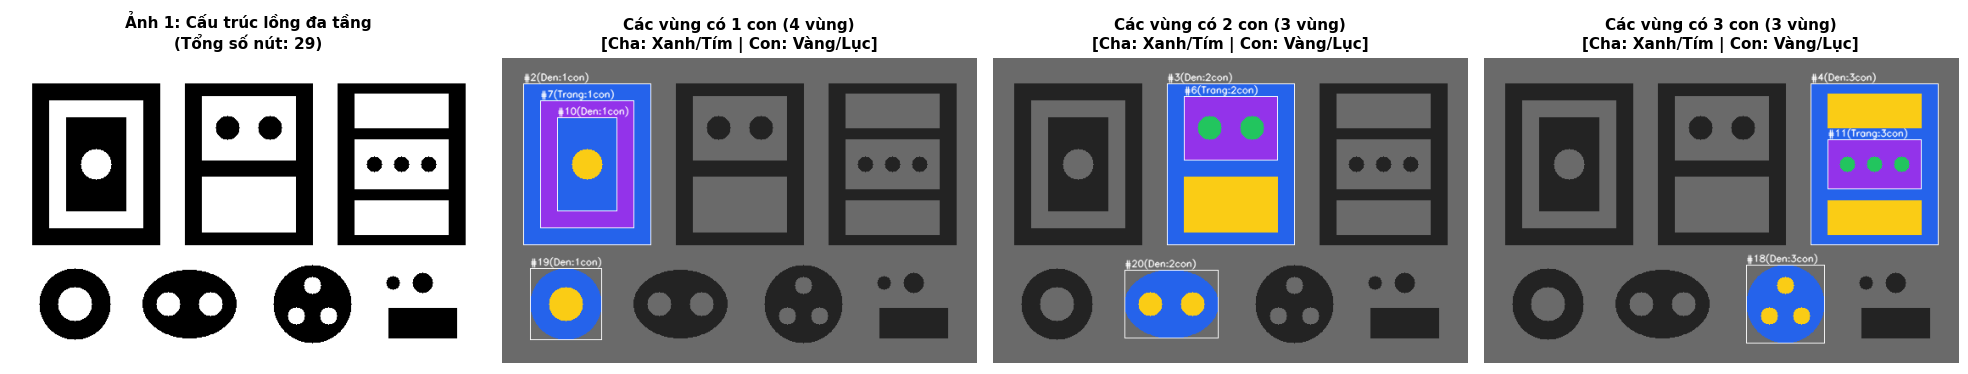

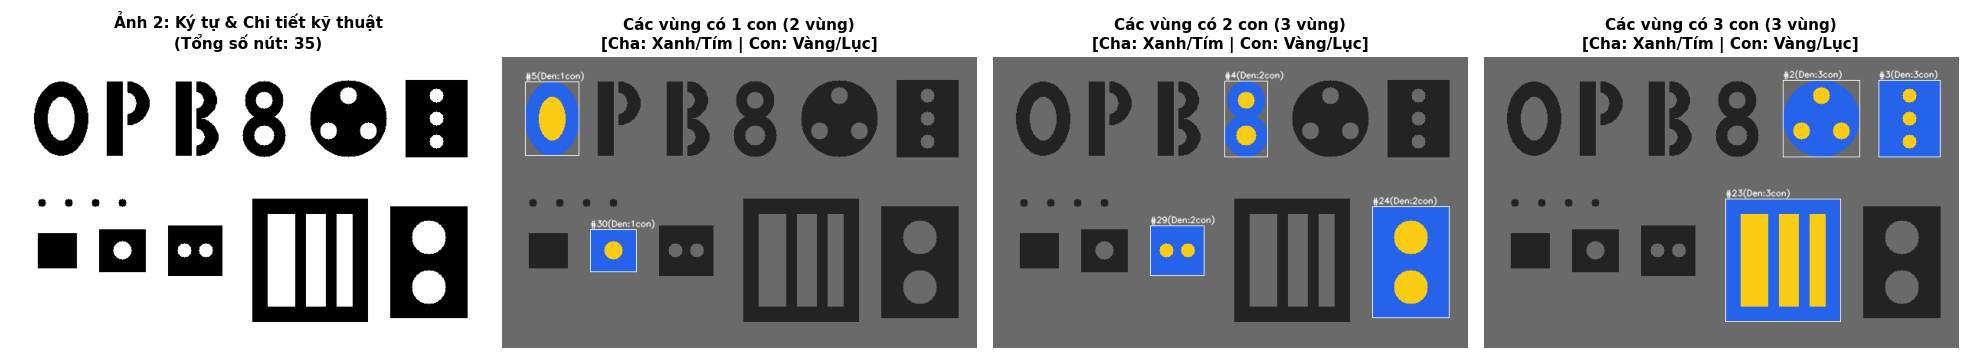

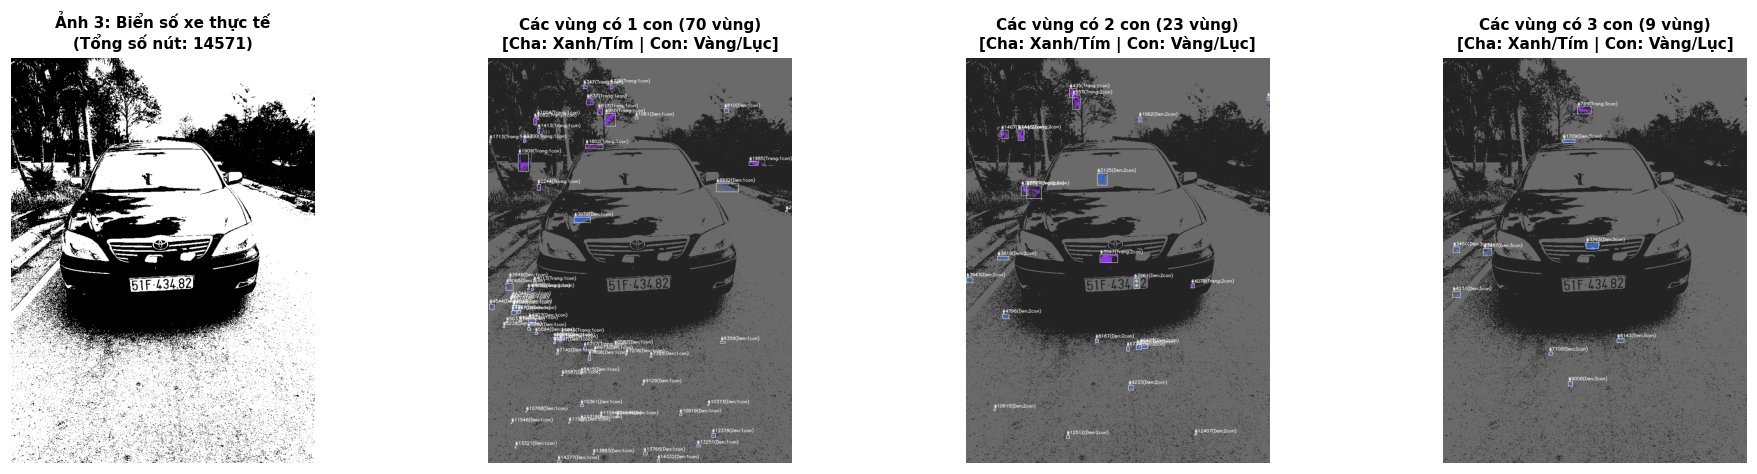

In [5]:
# 1.6. Thực nghiệm 2: Hiển thị các vùng có 1 con, 2 con, 3 con trên tập ảnh

def loc_vung_theo_so_con(danh_sach_nut, goc_id, so_con_can_tim, mau_chon=None, bo_qua_goc=True):
    """Lọc tất cả các vùng trong cây có số nút con trực tiếp đúng bằng so_con_can_tim."""
    ket_qua = []
    for nid, nut in danh_sach_nut.items():
        if bo_qua_goc and nid == goc_id:
            continue
        if mau_chon is not None and nut.mau != mau_chon:
            continue
        if nut.so_con == so_con_can_tim:
            ket_qua.append(nut)
    return ket_qua


def minh_hoa_vung_va_cac_con(I_np, danh_sach_nut, ban_do_nhan, ds_nut_cha):
    """
    Tô màu nổi bật cả Vùng Cha (vùng có k con) và các Vùng Con trực tiếp nằm bên trong nó:
    - Vùng Cha màu Đen -> tô Xanh Dương Đậm, các Con Trắng bên trong -> tô Vàng Tươi.
    - Vùng Cha màu Trắng -> tô Tím Đậm, các Con Đen bên trong -> tô Xanh Lá Tươi.
    """
    anh_vis = np.stack([I_np, I_np, I_np], axis=-1).astype(np.float32) * 0.28 + 35
    anh_vis = np.clip(anh_vis, 0, 255).astype(np.uint8)

    for nut_cha in ds_nut_cha:
        if nut_cha.mau == 0:
            mau_cha = (37, 99, 235)      # Xanh dương cho vùng cha Đen
            mau_con = (250, 204, 21)     # Vàng tươi cho các lỗ con Trắng
        else:
            mau_cha = (147, 51, 234)     # Tím cho vùng cha Trắng
            mau_con = (34, 197, 94)      # Xanh lá cho các đảo con Đen

        anh_vis[ban_do_nhan == nut_cha.id] = mau_cha
        for cid in nut_cha.con_ids:
            anh_vis[ban_do_nhan == cid] = mau_con

        cv2.rectangle(anh_vis, (nut_cha.x_min, nut_cha.y_min), (nut_cha.x_max, nut_cha.y_max), (255, 255, 255), 1)
        nhan_txt = f"#{nut_cha.id}({'Den' if nut_cha.mau==0 else 'Trang'}:{nut_cha.so_con}con)"
        cv2.putText(anh_vis, nhan_txt, (max(0, nut_cha.x_min), max(12, nut_cha.y_min - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.36, (255, 255, 255), 1, cv2.LINE_AA)

    return anh_vis


# Chạy thực nghiệm đồng loạt trên 3 ảnh: Ảnh 1 (Cây đa tầng), Ảnh 2 (Ký tự & Chi tiết), Ảnh 3 (Biển số xe thực tế)
tap_anh_thu_nghiem_con = [
    ('tap_anh/anh_1_cay_phan_cap.png', 'Ảnh 1: Cấu trúc lồng đa tầng'),
    ('tap_anh/anh_2_ky_tu_va_chi_tiet.png', 'Ảnh 2: Ký tự & Chi tiết kỹ thuật'),
    ('tap_anh/anh_3_bien_so_xe.jpg', 'Ảnh 3: Biển số xe thực tế')
]

for duong_dan, ten_mo_ta in tap_anh_thu_nghiem_con:
    im_g = cv2.imread(duong_dan, cv2.IMREAD_GRAYSCALE)
    im_np, t_val = nhi_phan_hoa(im_g)
    ds_nut, b_nhan, id_goc = xay_dung_cay_vung_nhi_phan(im_np)

    print("=" * 95)
    print(f"THỐNG KÊ CÁC VÙNG CÓ 1 CON, 2 CON, 3 CON TRÊN: {ten_mo_ta} ({os.path.basename(duong_dan)})")
    print("=" * 95)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
    axes[0].imshow(im_np, cmap='gray')
    axes[0].set_title(f"{ten_mo_ta}\n(Tổng số nút: {len(ds_nut)})", fontsize=10, fontweight='bold')
    axes[0].axis('off')

    for idx_k, k_con in enumerate([1, 2, 3]):
        vung_k_con = loc_vung_theo_so_con(ds_nut, id_goc, so_con_can_tim=k_con, bo_qua_goc=True)
        print(f" * Số vùng có đúng {k_con} con: {len(vung_k_con)} vùng")
        for n in vung_k_con:
            ds_mau_con = [f"#{cid}({ds_nut[cid].ten_mau.split()[0]})" for cid in n.con_ids]
            print(f"    -> Nút Cha #{n.id:02d} [{n.ten_mau:11s} | Tầng {n.do_sau} | A={n.dien_tich:5d} px] "
                  f"chứa {k_con} con: {', '.join(ds_mau_con)}")

        anh_k = minh_hoa_vung_va_cac_con(im_np, ds_nut, b_nhan, vung_k_con)
        axes[idx_k + 1].imshow(anh_k)
        axes[idx_k + 1].set_title(f"Các vùng có {k_con} con ({len(vung_k_con)} vùng)\n[Cha: Xanh/Tím | Con: Vàng/Lục]",
                                  fontsize=10, fontweight='bold')
        axes[idx_k + 1].axis('off')

    plt.tight_layout()
    plt.show()

---
## PHẦN 2: TRÍCH XUẤT ĐƯỜNG BIÊN VÀ PHÂN TÍCH TỈ LỆ KHOẢNG CÁCH $d_{\text{ảnh}} / d_{\text{biên}}$

### 2.1. Cơ sở toán học của tỉ lệ khoảng cách trên ảnh và khoảng cách trên biên

Giả sử sau khi nhị phân hóa, đường biên khép kín của một vùng đối tượng được biểu diễn bởi dãy điểm liên tiếp theo thứ tự dọc theo chu vi:
$$C = [P_0, P_1, P_2, \dots, P_{L-1}], \quad P_k = (x_k, y_k) \in \mathbb{Z}^2$$

Với hai điểm bất kỳ $P_i, P_j \in C$:
1. **Khoảng cách trên ảnh ($d_{\text{ảnh}}$ – Khoảng cách Euclid / dây cung):**
   $$d_{\text{ảnh}}(P_i, P_j) = \|P_i - P_j\|_2 = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}$$
2. **Khoảng cách trên biên ($d_{\text{biên}}$ – Độ dài cung dọc theo đường biên):**
   Gọi $s_k = \sum_{m=0}^{k-1} \|P_{m+1} - P_m\|_2$ là độ dài đường biên tích lũy từ $P_0$ đến $P_k$, và $S_{\text{total}} = s_{L-1} + \|P_0 - P_{L-1}\|_2$ là tổng chu vi đường biên khép kín. Khoảng cách ngắn nhất đi dọc theo đường biên giữa $P_i$ và $P_j$ là:
   $$d_{\text{biên}}(P_i, P_j) = \min\Big(|s_j - s_i|,\; S_{\text{total}} - |s_j - s_i|\Big)$$
3. **Tỉ lệ khoảng cách (Chord-to-Arc Distance Ratio):**
   $$R(P_i, P_j) = \frac{d_{\text{ảnh}}(P_i, P_j)}{d_{\text{biên}}(P_i, P_j)} \in (0, 1]$$

#### Ý nghĩa hình học khi lọc các điểm thỏa mãn $R < \tau$ (nhỏ hơn ngưỡng $\tau$):
- Trên đoạn biên thẳng hoặc cong thoai thoải: $d_{\text{ảnh}} \approx d_{\text{biên}} \implies R \approx 1$.
- Tại các **đỉnh nhọn, góc gấp khúc, khe lõm sâu, cổ thắt (bottleneck) hoặc các ngón tay**: hai điểm trên biên nằm rất gần nhau trong không gian ảnh ($d_{\text{ảnh}}$ nhỏ) nhưng để đi dọc theo biên từ điểm này sang điểm kia phải đi vòng một quãng đường dài ($d_{\text{biên}}$ lớn), dẫn đến:
  $$\frac{d_{\text{ảnh}}(P_i, P_j)}{d_{\text{biên}}(P_i, P_j)} < \tau$$
- Ta triển khai đồng thời cả **2 phương thức đánh giá**:
  1. **Tỉ lệ cục bộ quanh mỗi điểm biên $P_i$ (Local Window $w$):** Tính $R_{\text{local}}(P_i) = \frac{d_{\text{ảnh}}(P_{i-w}, P_{i+w})}{d_{\text{biên}}(P_{i-w}, P_{i+w})}$ để bắt các đỉnh nhọn và góc uốn cục bộ.
  2. **Tỉ lệ toàn cục nhỏ nhất tại mỗi điểm biên $P_i$ (Global Pairwise với $d_{\text{biên}}(P_i, P_j) \ge d_{\min}$):**
     $$R_{\text{min}}(P_i) = \min_{j \,:\, d_{\text{biên}}(P_i, P_j) \ge d_{\min}} \frac{d_{\text{ảnh}}(P_i, P_j)}{d_{\text{biên}}(P_i, P_j)}$$
     để bắt trọn vẹn cả các **vùng thắt cổ chai, khe hẹp chữ U, kẽ ngón tay và đỉnh nhọn**.

In [6]:
# 2.2. Cài đặt thuật toán trích xuất đường biên và tìm các điểm có d_ảnh / d_biên < ngưỡng

def trich_xuat_duong_bien(I_np, dien_tich_toi_thieu=100):
    """
    Trích xuất ảnh đường biên nhị phân (bằng phương pháp lân cận giống bài Biên)
    và danh sách các đường biên có thứ tự (ordered closed contours) của các vật thể.
    """
    # 1. Tính ảnh biên trực tiếp bằng kiểm tra lân cận 4-liên thông (theo chuẩn bài học Biên)
    H, W = I_np.shape
    anh_bien = np.zeros_like(I_np)
    for y in range(1, H - 1):
        for x in range(1, W - 1):
            if I_np[y, x] == 255:
                if (I_np[y-1, x] == 0 or I_np[y+1, x] == 0 or
                    I_np[y, x-1] == 0 or I_np[y, x+1] == 0):
                    anh_bien[y, x] = 255

    # 2. Trích xuất chuỗi tọa độ điểm biên liên tiếp P_0, P_1, ..., P_{L-1} để tính d_biên
    contours, _ = cv2.findContours(I_np, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    ds_duong_bien = []
    for cnt in contours:
        if cv2.contourArea(cnt) >= dien_tich_toi_thieu:
            pts = cnt[:, 0, :].astype(np.float64)  # Mảng (L, 2) gồm các tọa độ (x, y)
            ds_duong_bien.append(pts)

    return anh_bien, ds_duong_bien


def tinh_do_dai_tich_luy_bien(pts):
    """
    Tính mảng độ dài cung tích lũy s[k] dọc theo đường biên khép kín P_0, ..., P_{L-1}
    và tổng chu vi S_total.
    """
    diffs = np.roll(pts, -1, axis=0) - pts
    step_lengths = np.hypot(diffs[:, 0], diffs[:, 1])
    s = np.zeros(len(pts), dtype=np.float64)
    s[1:] = np.cumsum(step_lengths[:-1])
    S_total = float(np.sum(step_lengths))
    return s, S_total


def phan_tich_ti_le_khoang_cach_bien(pts, nguong_tau=0.55, d_bien_toi_thieu=18.0, d_bien_toi_da=110.0, ban_kinh_cuc_bo=16):
    """
    Với mỗi điểm P_i trên đường biên khép kín:
    1. Tính tỉ lệ nhỏ nhất trên phạm vi cung [d_bien_toi_thieu, d_bien_toi_da]:
       R_min(P_i) = min_{j: d_min <= d_bien(P_i, P_j) <= d_max} [ d_anh(P_i, P_j) / d_bien(P_i, P_j) ]
       (Phát hiện cả cổ thắt bottleneck, khe hẹp chữ U, kẽ ngón tay và đỉnh nhọn).
    2. Tính tỉ lệ cửa sổ đối xứng cục bộ quanh P_i (giữa P_{i-w} và P_{i+w}):
       R_local(P_i) = d_anh(P_{i-w}, P_{i+w}) / d_bien(P_{i-w}, P_{i+w})
       (Phát hiện trực tiếp các đỉnh nhọn và góc gấp khúc trên biên).
    3. Xác định các điểm trên biên thỏa mãn tỉ lệ < nguong_tau.
    """
    L = len(pts)
    s, S_total = tinh_do_dai_tich_luy_bien(pts)

    # Ma trận khoảng cách trên ảnh d_ảnh(P_i, P_j) = ||P_i - P_j||_2
    dx = pts[:, 0][:, None] - pts[:, 0][None, :]
    dy = pts[:, 1][:, None] - pts[:, 1][None, :]
    mat_d_anh = np.hypot(dx, dy)

    # Ma trận khoảng cách trên biên d_biên(P_i, P_j) = min(|s_i - s_j|, S_total - |s_i - s_j|)
    ds_abs = np.abs(s[:, None] - s[None, :])
    mat_d_bien = np.minimum(ds_abs, S_total - ds_abs)

    # Chỉ xét các cặp điểm có khoảng cách trên biên nằm trong [d_bien_toi_thieu, d_bien_toi_da]
    hop_le = (mat_d_bien >= d_bien_toi_thieu) & (mat_d_bien <= d_bien_toi_da)
    mat_ti_le = np.full((L, L), np.inf, dtype=np.float64)
    mat_ti_le[hop_le] = mat_d_anh[hop_le] / mat_d_bien[hop_le]

    # Tỉ lệ nhỏ nhất tại mỗi điểm P_i và chỉ số điểm đối ứng j* tạo ra tỉ lệ nhỏ nhất đó
    chi_so_doi_ung = np.argmin(mat_ti_le, axis=1)
    ti_le_toan_cuc = mat_ti_le[np.arange(L), chi_so_doi_ung]

    # Tỉ lệ cục bộ quanh P_i với bán kính cung w = ban_kinh_cuc_bo
    w = min(ban_kinh_cuc_bo, max(2, L // 6))
    idx_trai = (np.arange(L) - w) % L
    idx_phai = (np.arange(L) + w) % L
    d_anh_local = mat_d_anh[idx_trai, idx_phai]
    d_bien_local = mat_d_bien[idx_trai, idx_phai]
    ti_le_cuc_bo = d_anh_local / np.maximum(d_bien_local, 1e-6)

    # Mặt nạ các điểm biên thỏa mãn tỉ lệ < ngưỡng tau
    mask_toan_cuc = ti_le_toan_cuc < nguong_tau
    mask_cuc_bo = ti_le_cuc_bo < nguong_tau

    return {
        "s": s,
        "S_total": S_total,
        "mat_d_anh": mat_d_anh,
        "mat_d_bien": mat_d_bien,
        "ti_le_toan_cuc": ti_le_toan_cuc,
        "chi_so_doi_ung": chi_so_doi_ung,
        "ti_le_cuc_bo": ti_le_cuc_bo,
        "mask_toan_cuc": mask_toan_cuc,
        "mask_cuc_bo": mask_cuc_bo
    }

THỰC NGHIỆM PHẦN 2.1: TRÍCH XUẤT BIÊN & TỈ LỆ d_ảnh / d_biên TRÊN 'anh_5_hinh_dang_bien.png'
Số đường biên đối tượng trích xuất được: 3
 - Ngưỡng tau = 0.40: Tìm thấy  482 / 2027 điểm biên ( 23.8%) có d_ảnh / d_biên < 0.4
 - Ngưỡng tau = 0.55: Tìm thấy  830 / 2027 điểm biên ( 40.9%) có d_ảnh / d_biên < 0.55
 - Ngưỡng tau = 0.70: Tìm thấy 1216 / 2027 điểm biên ( 60.0%) có d_ảnh / d_biên < 0.7


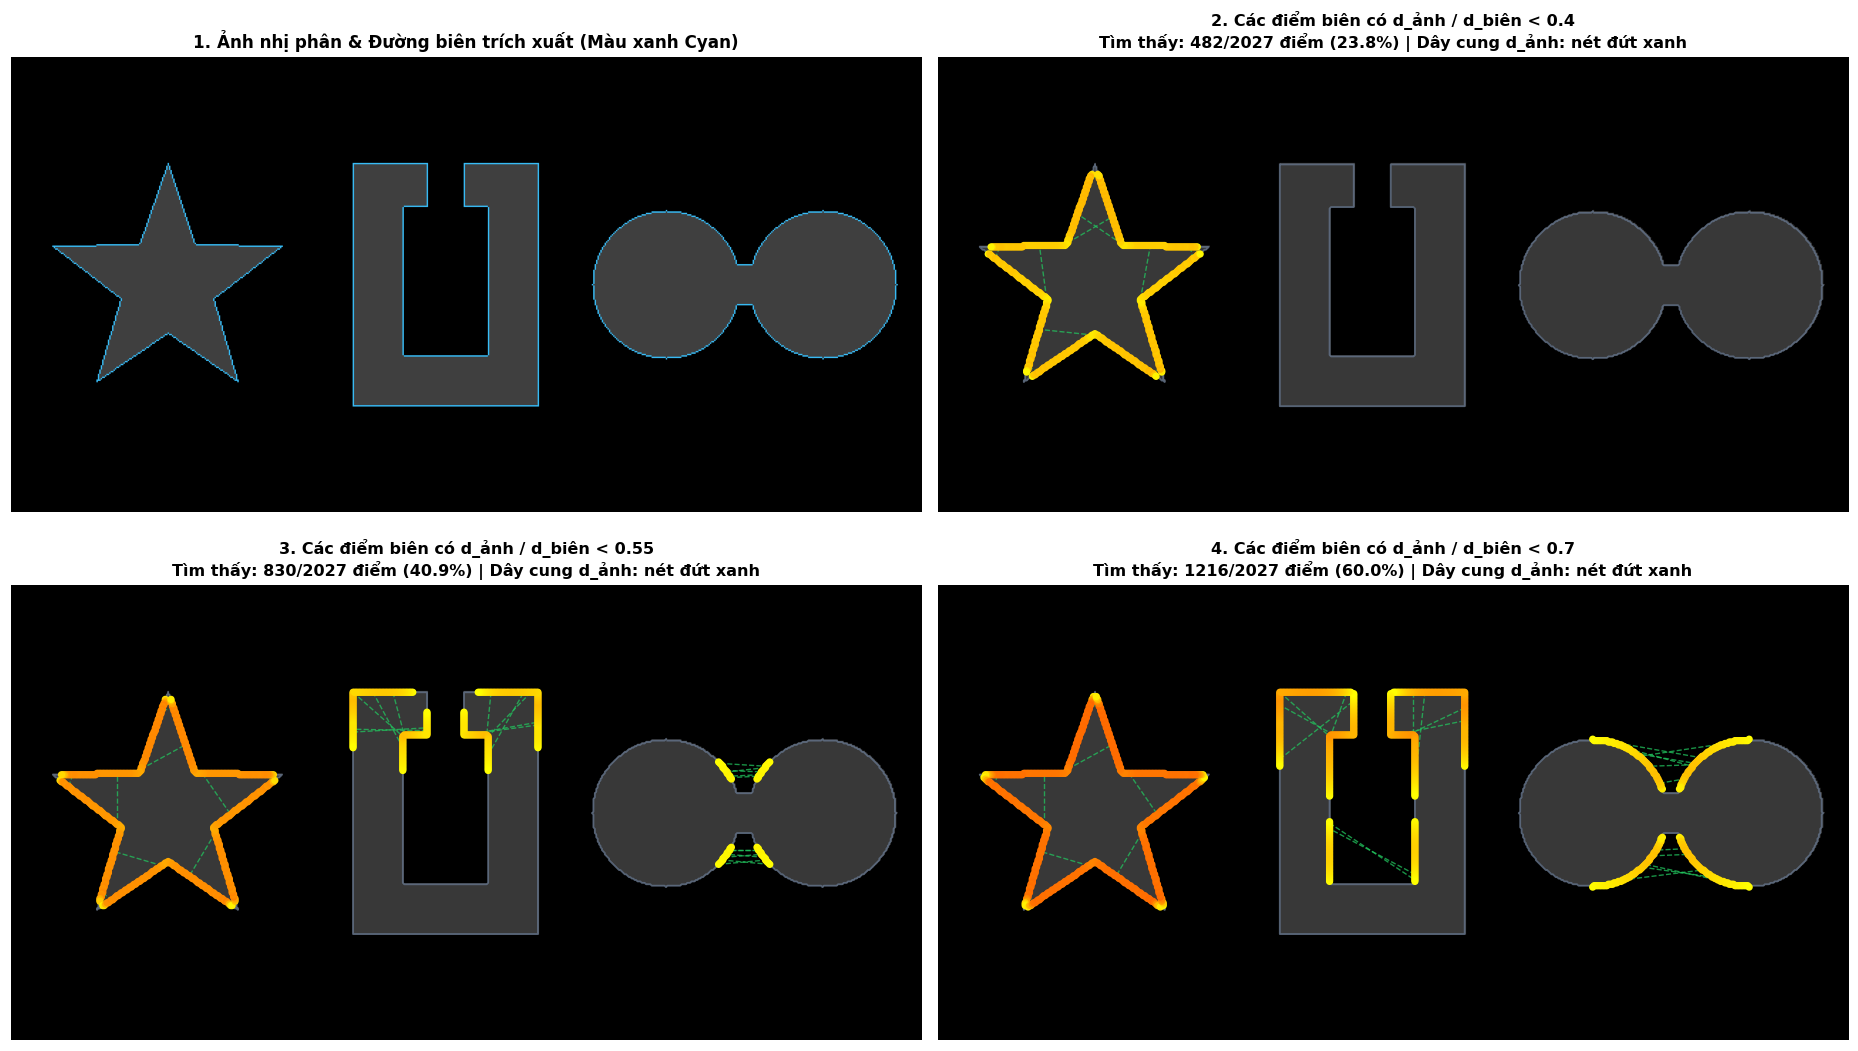

In [7]:
# 2.3. Thực nghiệm 1: Phân tích tỉ lệ d_ảnh / d_biên trên các hình dạng đặc trưng (Ngôi sao, Chữ U, Quả tạ)

I_goc_5 = cv2.imread('tap_anh/anh_5_hinh_dang_bien.png', cv2.IMREAD_GRAYSCALE)
I_np_5, t_5 = nhi_phan_hoa(I_goc_5)
anh_bien_5, ds_bien_5 = trich_xuat_duong_bien(I_np_5, dien_tich_toi_thieu=200)

print("=" * 95)
print(f"THỰC NGHIỆM PHẦN 2.1: TRÍCH XUẤT BIÊN & TỈ LỆ d_ảnh / d_biên TRÊN 'anh_5_hinh_dang_bien.png'")
print("=" * 95)
print(f"Số đường biên đối tượng trích xuất được: {len(ds_bien_5)}")

# Khảo sát với 3 mức ngưỡng tau khác nhau: 0.40 (rất khắt khe), 0.55 (vừa), 0.70 (rộng)
cac_nguong_tau = [0.40, 0.55, 0.70]

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
axes = axes.flatten()

# Ô 1: Hiển thị ảnh nhị phân gốc và đường biên trích xuất
anh_gop_bien = np.stack([I_np_5 * 0.25, I_np_5 * 0.25, I_np_5 * 0.25], axis=-1).astype(np.uint8)
anh_gop_bien[anh_bien_5 > 0] = (56, 189, 248)  # Biên màu xanh cyan sáng
axes[0].imshow(anh_gop_bien)
axes[0].set_title("1. Ảnh nhị phân & Đường biên trích xuất (Màu xanh Cyan)", fontsize=11, fontweight='bold')
axes[0].axis('off')

# Ô 2, 3, 4: Hiển thị các điểm trên biên có d_ảnh / d_biên < tau với từng ngưỡng tau
for idx_t, tau in enumerate(cac_nguong_tau):
    ax = axes[idx_t + 1]
    nen_mo = np.stack([I_np_5 * 0.22, I_np_5 * 0.22, I_np_5 * 0.22], axis=-1).astype(np.uint8)
    ax.imshow(nen_mo)

    tong_diem_bien = 0
    tong_diem_thoa_man = 0

    for idx_c, pts in enumerate(ds_bien_5):
        kq = phan_tich_ti_le_khoang_cach_bien(
            pts, nguong_tau=tau, d_bien_toi_thieu=20.0, d_bien_toi_da=105.0, ban_kinh_cuc_bo=16
        )
        mask_chon = kq["mask_toan_cuc"]
        so_chon = int(np.sum(mask_chon))
        tong_diem_bien += len(pts)
        tong_diem_thoa_man += so_chon

        # Vẽ toàn bộ đường biên bằng màu xám xanh mảnh
        ax.plot(pts[:, 0], pts[:, 1], color='#64748B', linewidth=1.2, alpha=0.8)

        # Vẽ nổi bật các điểm biên thỏa mãn d_ảnh / d_biên < tau bằng màu Đỏ - Vàng
        if so_chon > 0:
            pts_chon = pts[mask_chon]
            ti_le_chon = kq["ti_le_toan_cuc"][mask_chon]
            sc = ax.scatter(pts_chon[:, 0], pts_chon[:, 1], c=ti_le_chon, cmap='autumn',
                            vmin=0.0, vmax=tau, s=14, zorder=4)

            # Vẽ một số dây cung đại diện nối cặp (P_i, P_j*) có tỉ lệ nhỏ nhất để thấy rõ d_ảnh << d_biên
            cac_chi_so_chon = np.where(mask_chon)[0]
            buoc_nhay = max(1, len(cac_chi_so_chon) // 10)
            for i_pt in cac_chi_so_chon[::buoc_nhay]:
                j_pt = kq["chi_so_doi_ung"][i_pt]
                ax.plot([pts[i_pt, 0], pts[j_pt, 0]], [pts[i_pt, 1], pts[j_pt, 1]],
                        color='#22C55E', linestyle='--', linewidth=0.9, alpha=0.75, zorder=3)

    ty_le_phan_tram = 100.0 * tong_diem_thoa_man / max(1, tong_diem_bien)
    print(f" - Ngưỡng tau = {tau:.2f}: Tìm thấy {tong_diem_thoa_man:4d} / {tong_diem_bien} điểm biên "
          f"({ty_le_phan_tram:5.1f}%) có d_ảnh / d_biên < {tau}")

    ax.set_title(f"{idx_t + 2}. Các điểm biên có d_ảnh / d_biên < {tau}\n"
                 f"Tìm thấy: {tong_diem_thoa_man}/{tong_diem_bien} điểm ({ty_le_phan_tram:.1f}%) | Dây cung d_ảnh: nét đứt xanh",
                 fontsize=10.5, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

THỰC NGHIỆM PHẦN 2.2: PHÂN TÍCH ĐƯỜNG BIÊN ẢNH THỰC TẾ BÀN TAY ('anh_4_ban_tay.jpeg')
 - Ngưỡng nhị phân Otsu: T = 229
 - Tổng số điểm trên đường biên bàn tay: 819 điểm | Tổng chu vi S_total = 883.2 px
 - Chế độ Cục bộ (w=18, tau=0.72): Phát hiện 255 điểm tại các ĐẦU NGÓN TAY & KẼ NGÓN TAY
 - Chế độ Toàn cục (d_bien>=35, tau=0.42): Phát hiện 561 điểm dọc theo THÂN NGÓN & KHE HẸP


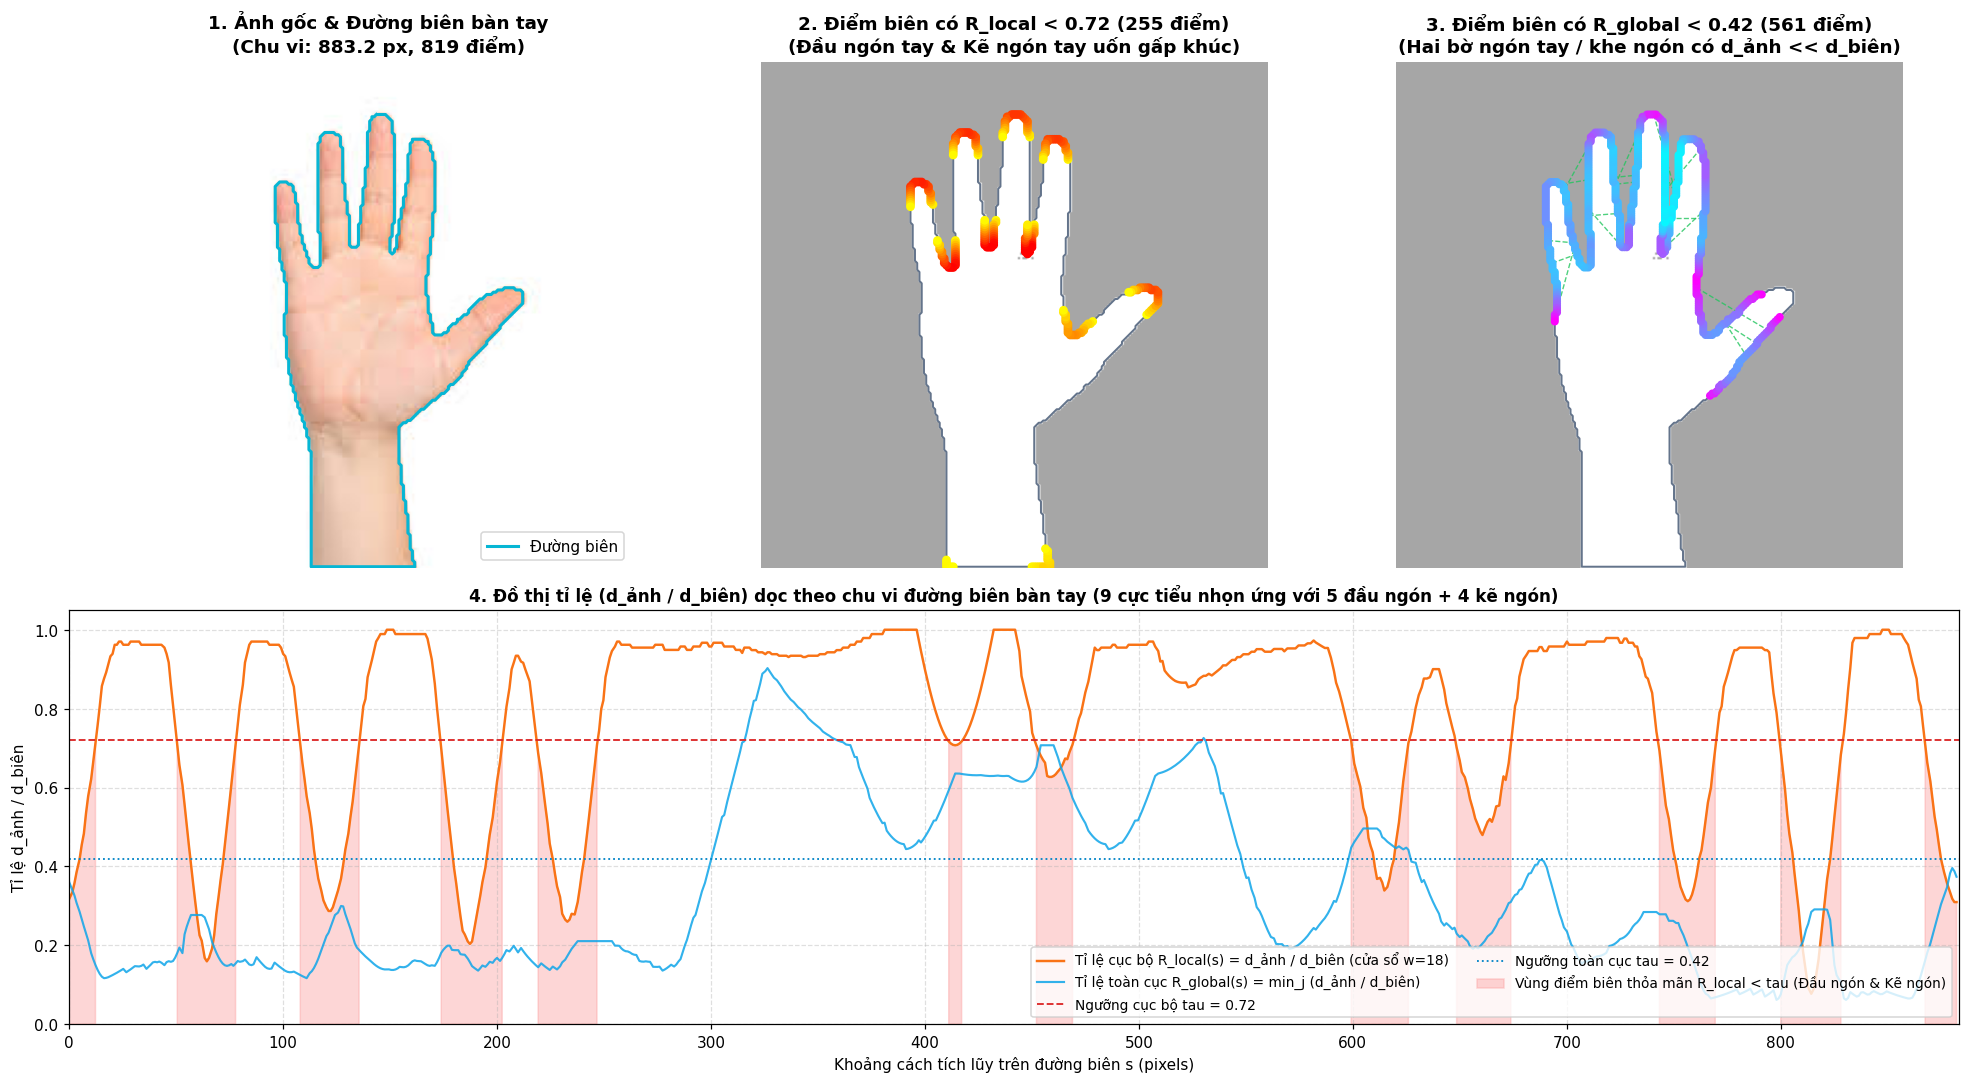

In [8]:
# 2.4. Thực nghiệm 2: Phân tích tỉ lệ d_ảnh / d_biên trên ảnh thực tế Bàn tay ('anh_4_ban_tay.jpeg')

I_goc_4 = cv2.imread('tap_anh/anh_4_ban_tay.jpeg')
I_rgb_4 = cv2.cvtColor(I_goc_4, cv2.COLOR_BGR2RGB)
# Nhị phân hóa đảo ngược (dao_nguoc=True) để vùng bàn tay có giá trị 255 (trắng) trên nền 0 (đen)
I_np_4, t_4 = nhi_phan_hoa(I_goc_4, dao_nguoc=True)
anh_bien_4, ds_bien_4 = trich_xuat_duong_bien(I_np_4, dien_tich_toi_thieu=500)

# Lấy đường biên lớn nhất (đường biên bàn tay)
bien_ban_tay = max(ds_bien_4, key=lambda c: len(c))

# Phân tích tỉ lệ d_ảnh / d_biên trên đường biên bàn tay
nguong_cuc_bo = 0.72
nguong_toan_cuc = 0.42
kq_tay_local = phan_tich_ti_le_khoang_cach_bien(
    bien_ban_tay, nguong_tau=nguong_cuc_bo, d_bien_toi_thieu=18.0, d_bien_toi_da=95.0, ban_kinh_cuc_bo=18
)
kq_tay_global = phan_tich_ti_le_khoang_cach_bien(
    bien_ban_tay, nguong_tau=nguong_toan_cuc, d_bien_toi_thieu=24.0, d_bien_toi_da=95.0, ban_kinh_cuc_bo=18
)

so_diem_local = int(np.sum(kq_tay_local["mask_cuc_bo"]))
so_diem_global = int(np.sum(kq_tay_global["mask_toan_cuc"]))

print("=" * 95)
print("THỰC NGHIỆM PHẦN 2.2: PHÂN TÍCH ĐƯỜNG BIÊN ẢNH THỰC TẾ BÀN TAY ('anh_4_ban_tay.jpeg')")
print("=" * 95)
print(f" - Ngưỡng nhị phân Otsu: T = {t_4:.0f}")
print(f" - Tổng số điểm trên đường biên bàn tay: {len(bien_ban_tay)} điểm | Tổng chu vi S_total = {kq_tay_local['S_total']:.1f} px")
print(f" - Chế độ Cục bộ (w=18, tau={nguong_cuc_bo}): Phát hiện {so_diem_local} điểm tại các ĐẦU NGÓN TAY & KẼ NGÓN TAY")
print(f" - Chế độ Toàn cục (d_bien>=35, tau={nguong_toan_cuc}): Phát hiện {so_diem_global} điểm dọc theo THÂN NGÓN & KHE HẸP")

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.1, 0.9])

# 1. Ảnh gốc & Đường biên trích xuất
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(I_rgb_4)
ax1.plot(bien_ban_tay[:, 0], bien_ban_tay[:, 1], color='#06B6D4', linewidth=2.0, label='Đường biên')
ax1.set_title(f"1. Ảnh gốc & Đường biên bàn tay\n(Chu vi: {kq_tay_local['S_total']:.1f} px, {len(bien_ban_tay)} điểm)", fontweight='bold')
ax1.legend(loc='lower right')
ax1.axis('off')

# 2. Chế độ Cục bộ: Các điểm biên có d_ảnh / d_biên < ngưỡng tại đầu ngón & kẽ ngón
ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(I_np_4, cmap='gray', alpha=0.35)
ax2.plot(bien_ban_tay[:, 0], bien_ban_tay[:, 1], color='#64748B', linewidth=1.3)
pts_loc = bien_ban_tay[kq_tay_local["mask_cuc_bo"]]
val_loc = kq_tay_local["ti_le_cuc_bo"][kq_tay_local["mask_cuc_bo"]]
ax2.scatter(pts_loc[:, 0], pts_loc[:, 1], c=val_loc, cmap='autumn', vmin=0.2, vmax=nguong_cuc_bo, s=22, zorder=4)
ax2.set_title(f"2. Điểm biên có R_local < {nguong_cuc_bo} ({so_diem_local} điểm)\n(Đầu ngón tay & Kẽ ngón tay uốn gấp khúc)", fontweight='bold')
ax2.axis('off')

# 3. Chế độ Toàn cục: Các điểm biên và dây cung nối qua ngón tay / khe ngón tay
ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(I_np_4, cmap='gray', alpha=0.35)
ax3.plot(bien_ban_tay[:, 0], bien_ban_tay[:, 1], color='#64748B', linewidth=1.3)
pts_glo = bien_ban_tay[kq_tay_global["mask_toan_cuc"]]
val_glo = kq_tay_global["ti_le_toan_cuc"][kq_tay_global["mask_toan_cuc"]]
ax3.scatter(pts_glo[:, 0], pts_glo[:, 1], c=val_glo, cmap='cool', vmin=0.05, vmax=nguong_toan_cuc, s=18, zorder=4)

idx_glo = np.where(kq_tay_global["mask_toan_cuc"])[0]
for i_pt in idx_glo[::max(1, len(idx_glo)//18)]:
    j_pt = kq_tay_global["chi_so_doi_ung"][i_pt]
    ax3.plot([bien_ban_tay[i_pt, 0], bien_ban_tay[j_pt, 0]],
             [bien_ban_tay[i_pt, 1], bien_ban_tay[j_pt, 1]],
             color='#22C55E', linestyle='--', linewidth=0.9, alpha=0.8)
ax3.set_title(f"3. Điểm biên có R_global < {nguong_toan_cuc} ({so_diem_global} điểm)\n(Hai bờ ngón tay / khe ngón có d_ảnh << d_biên)", fontweight='bold')
ax3.axis('off')

# 4. Đồ thị biến thiên tỉ lệ d_ảnh / d_biên dọc theo chiều dài đường biên s
ax4 = fig.add_subplot(gs[1, :])
s_arr = kq_tay_local["s"]
r_loc_arr = kq_tay_local["ti_le_cuc_bo"]
r_glo_arr = kq_tay_global["ti_le_toan_cuc"]

ax4.plot(s_arr, r_loc_arr, color='#F97316', linewidth=1.6, label='Tỉ lệ cục bộ R_local(s) = d_ảnh / d_biên (cửa sổ w=18)')
ax4.plot(s_arr, r_glo_arr, color='#0EA5E9', linewidth=1.4, alpha=0.85, label='Tỉ lệ toàn cục R_global(s) = min_j (d_ảnh / d_biên)')
ax4.axhline(nguong_cuc_bo, color='#DC2626', linestyle='--', linewidth=1.2, label=f'Ngưỡng cục bộ tau = {nguong_cuc_bo}')
ax4.axhline(nguong_toan_cuc, color='#0284C7', linestyle=':', linewidth=1.2, label=f'Ngưỡng toàn cục tau = {nguong_toan_cuc}')

# Tô vùng dưới ngưỡng
ax4.fill_between(s_arr, 0, r_loc_arr, where=(r_loc_arr < nguong_cuc_bo), color='#FCA5A5', alpha=0.45,
                 label='Vùng điểm biên thỏa mãn R_local < tau (Đầu ngón & Kẽ ngón)')

ax4.set_title("4. Đồ thị tỉ lệ (d_ảnh / d_biên) dọc theo chu vi đường biên bàn tay (9 cực tiểu nhọn ứng với 5 đầu ngón + 4 kẽ ngón)",
              fontsize=11, fontweight='bold')
ax4.set_xlabel("Khoảng cách tích lũy trên đường biên s (pixels)", fontsize=10)
ax4.set_ylabel("Tỉ lệ d_ảnh / d_biên", fontsize=10)
ax4.set_ylim(0, 1.05)
ax4.set_xlim(0, kq_tay_local["S_total"])
ax4.grid(True, linestyle='--', alpha=0.4)
ax4.legend(loc='lower right', ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

---
## TỔNG KẾT THỰC NGHIỆM LAB 07

1. **Cấu trúc cây phân cấp các vùng nhị phân (Đen $\leftrightarrow$ Trắng):**
   - Bằng cách kết hợp thuật toán duyệt chiều rộng **BFS** với quy tắc liên thông cặp **(8-liên thông cho vùng Đen `0`, 4-liên thông cho vùng Trắng `255`)** và tra cứu điểm lân cận ngay phía trên điểm cực trị trên-trái $(r_0 - 1, c_0)$, ta xây dựng được chính xác cây bao hàm phân cấp trong thời gian tuyến tính $O(H \times W)$.
   - Mọi vùng Đen chứa lỗ Trắng đều nhận các lỗ Trắng đó làm **nút con trực tiếp**, và ngược lại mọi vùng Trắng chứa đảo Đen đều nhận các đảo Đen đó làm **nút con trực tiếp**.
   - **Ứng dụng truy vấn trên cây:**
     - **Lọc theo kích thước và diện tích:** Cho phép tách riêng các nhóm chi tiết nhỏ, ký tự vừa, hoặc khung lớn, cũng như tách chính xác các ký tự và lỗ ký tự trên ảnh biển số xe thực tế.
     - **Lọc theo số lượng con (1 con, 2 con, 3 con):** Cho phép phân loại hình thái học topo (Euler / Genus) của đối tượng mà không phụ thuộc phép quay hay tỉ lệ co giãn:
       - **1 con:** Chữ `O, P, A, D, 0, 4, 6, 9`, vòng đệm 1 lỗ.
       - **2 con:** Chữ `B`, số `8`, chi tiết mặt nạ 2 lỗ.
       - **3 con:** Mặt bích 3 lỗ, cúc áo 3 lỗ, thanh gá 3 lỗ.

2. **Trích xuất đường biên và phân tích tỉ lệ khoảng cách $d_{\text{ảnh}} / d_{\text{biên}} < \tau$:**
   - Tỉ lệ $R(P_i, P_j) = \frac{d_{\text{ảnh}}(P_i, P_j)}{d_{\text{biên}}(P_i, P_j)} \in (0, 1]$ đo mức độ uốn gập hoặc thắt hẹp của đường biên.
   - Khi lọc các điểm trên biên có $R < \tau$:
     - **Chế độ cửa sổ cung cục bộ ($R_{\text{local}} < \tau$):** Phát hiện chính xác các điểm có độ cong lớn như **đỉnh ngôi sao, góc nhọn, 5 đầu ngón tay và 4 kẽ ngón tay**.
     - **Chế độ cặp điểm toàn cục ($R_{\text{global}} < \tau$):** Phát hiện chính xác các vùng **cổ thắt (bottleneck), khe hẹp chữ U, và thân các ngón tay** nơi hai bờ biên nằm gần nhau trên ảnh nhưng cách xa nhau nếu đi dọc theo chu vi biên.